Análisis Exploratorio

--- Primeras filas del DataFrame ---
                        Date      City     CO  CO2   NO2  SO2    O3  PM2.5  \
0  2024-01-01 00:00:00+00:00  Brasilia  323.0  NaN  23.8  2.8  42.0   12.0   
1  2024-01-01 01:00:00+00:00  Brasilia  318.0  NaN  21.9  2.7  40.0   12.5   
2  2024-01-01 02:00:00+00:00  Brasilia  309.0  NaN  19.2  2.6  39.0   12.1   
3  2024-01-01 03:00:00+00:00  Brasilia  295.0  NaN  16.3  2.4  38.0   11.4   
4  2024-01-01 04:00:00+00:00  Brasilia  270.0  NaN  13.0  2.1  40.0   10.2   

   PM10        AQI  
0  17.1  16.800000  
1  17.9  16.000000  
2  17.3  15.599999  
3  16.2  15.200000  
4  14.6  16.000000  


--- Información del DataFrame ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52704 entries, 0 to 52703
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype              
---  ------  --------------  -----              
 0   Date    52704 non-null  datetime64[ns, UTC]
 1   City    52704 non-null  object             
 2   CO      52704 non-null

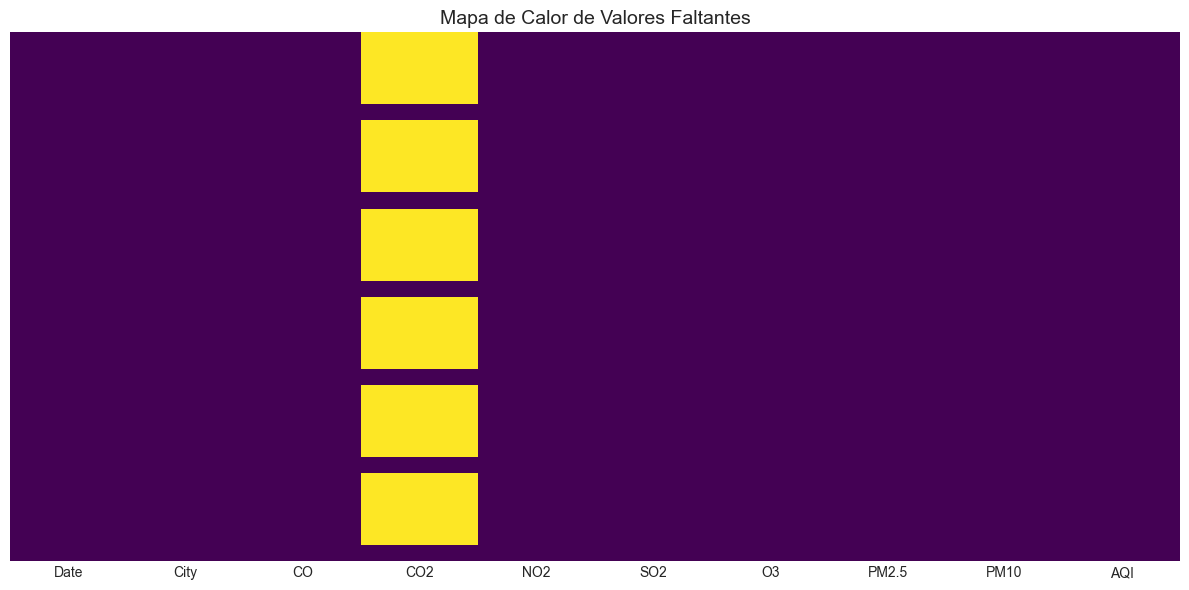

--- Generando Histogramas de Variables Numéricas ---


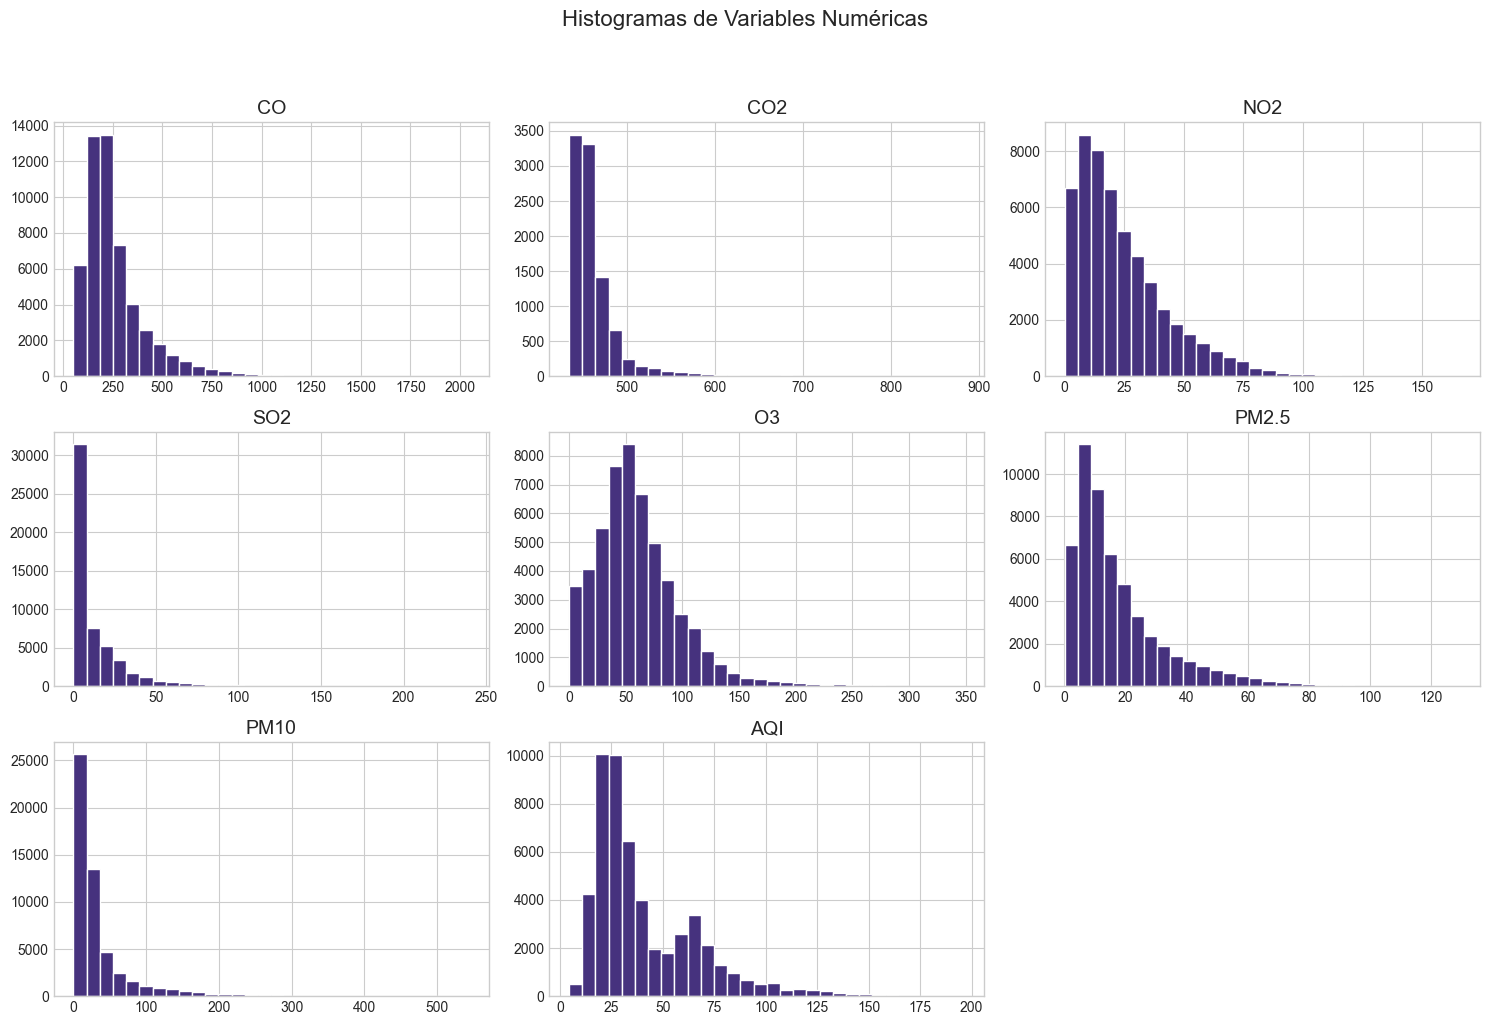

--- Generando Boxplots de Variables Numéricas ---


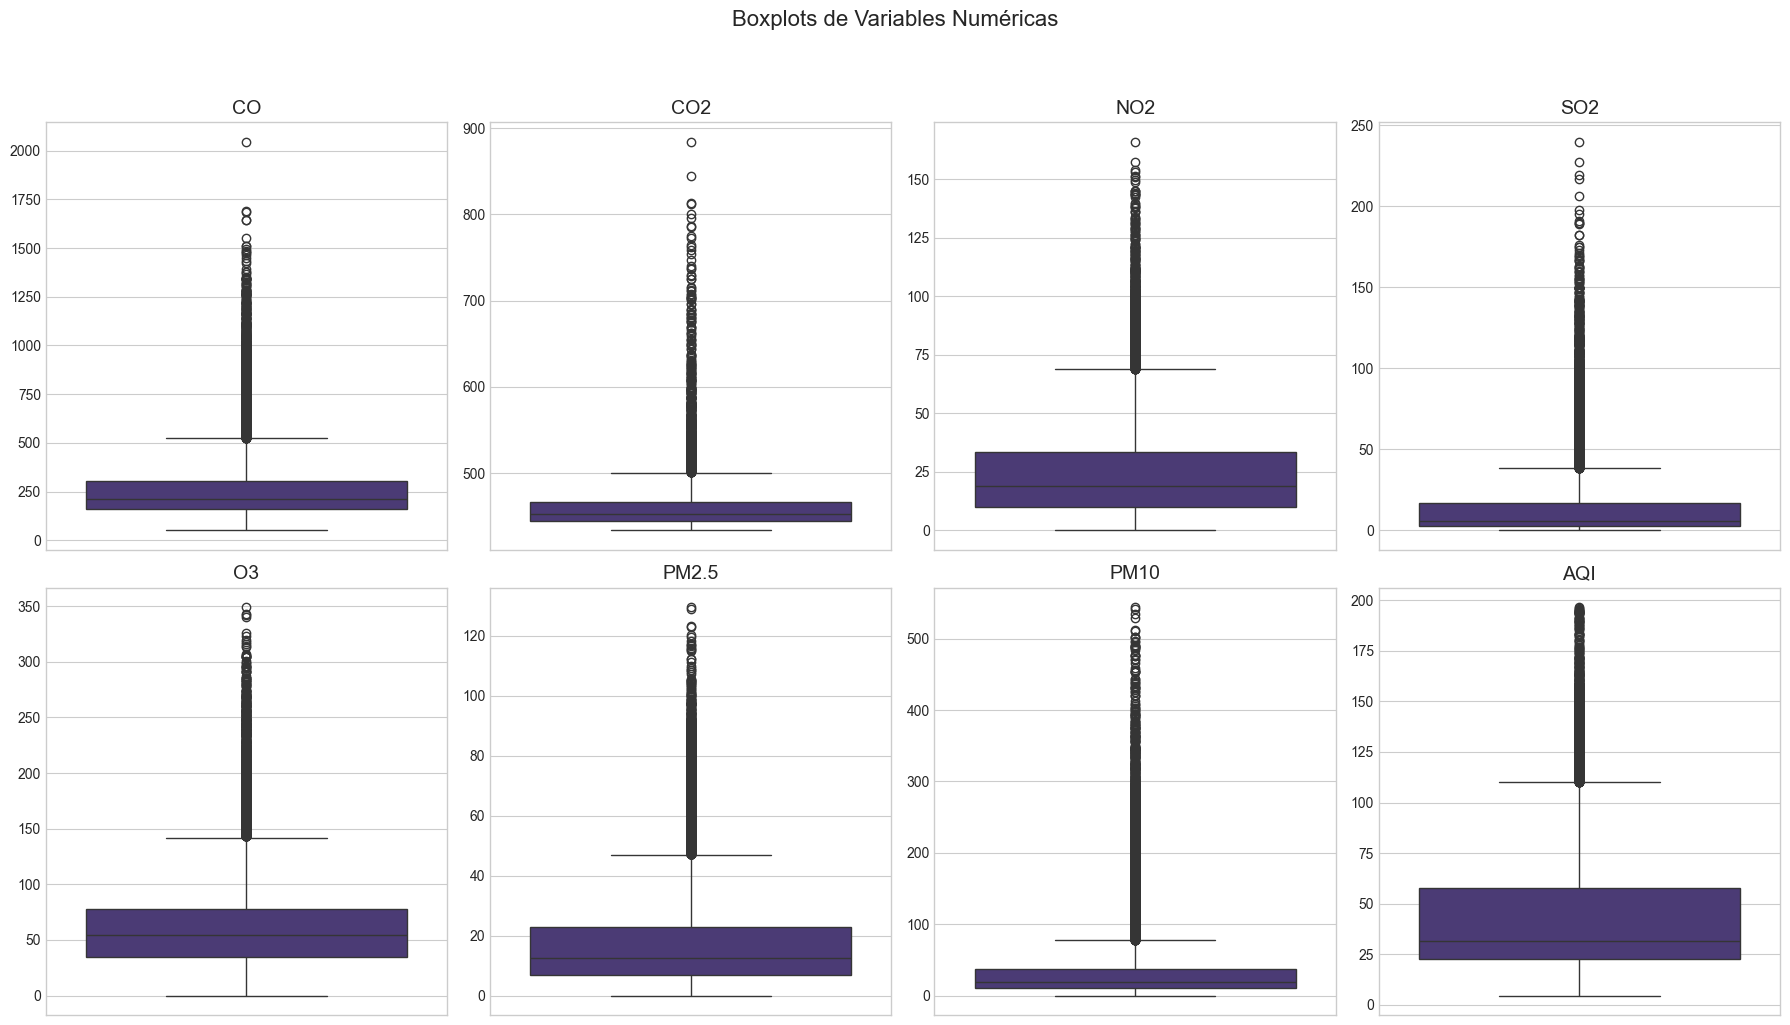

--- Generando Boxplots de Variables Numéricas por Ciudad ---


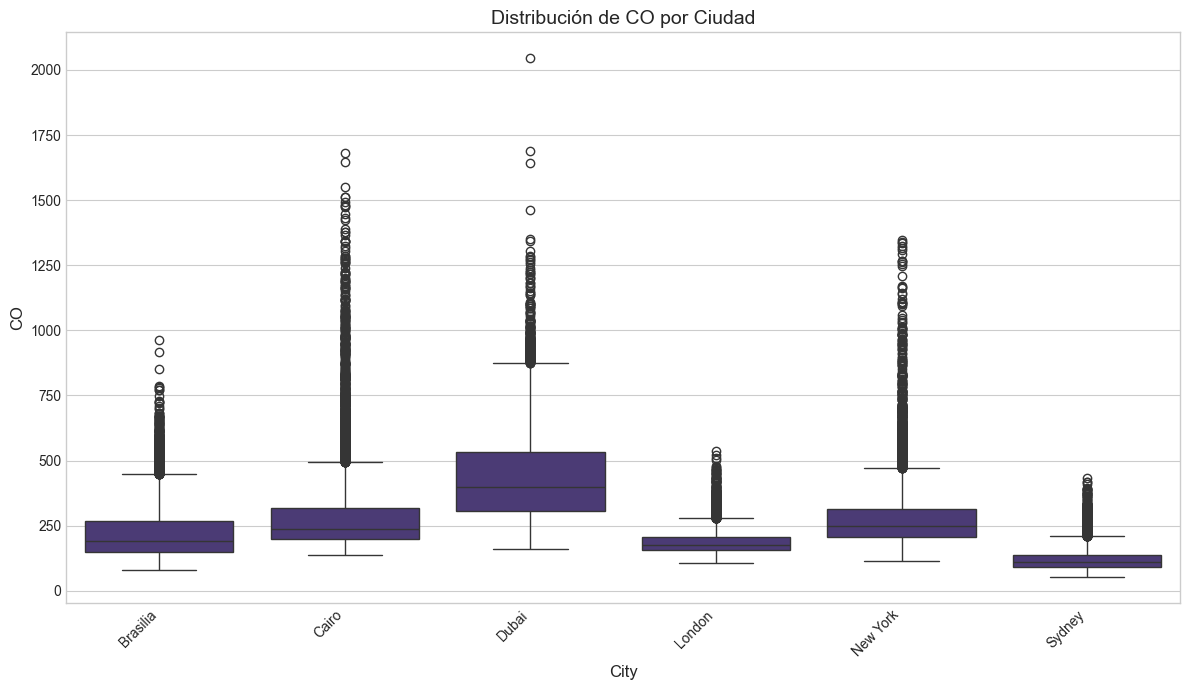

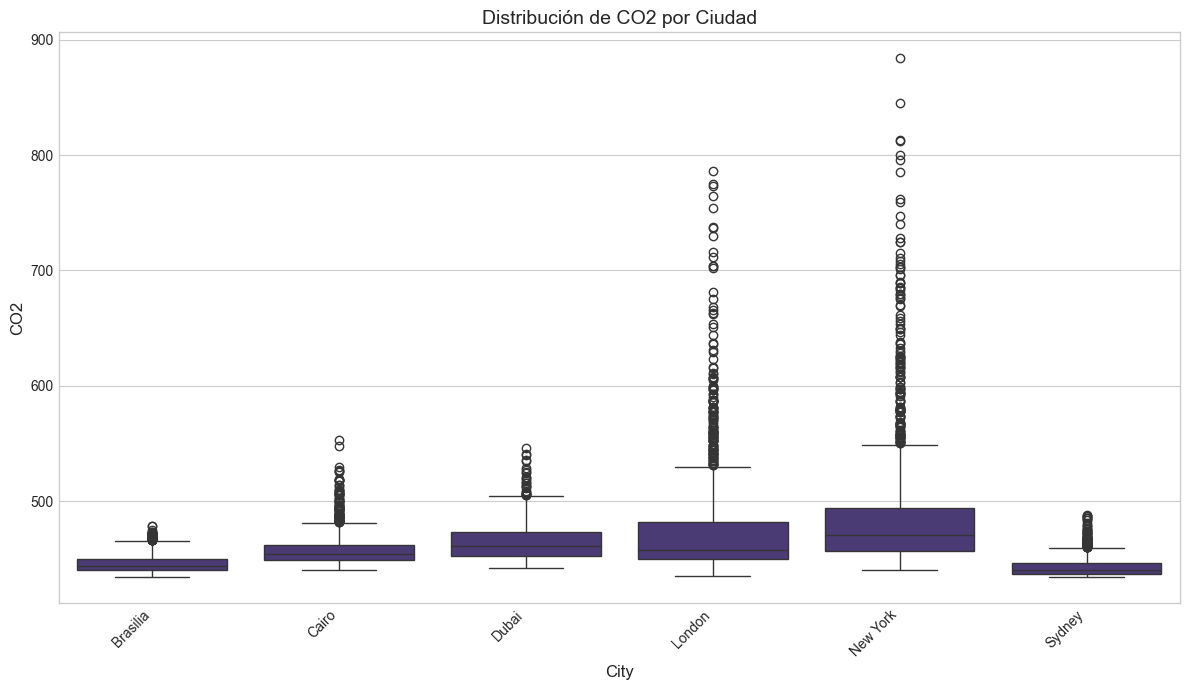

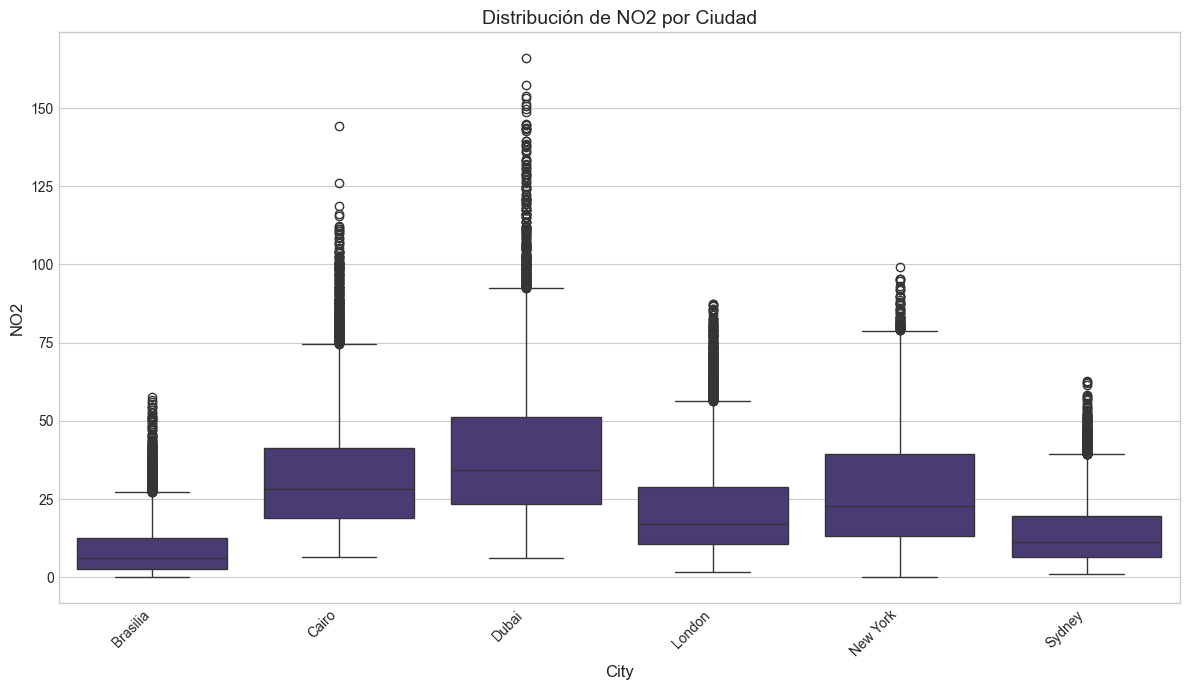

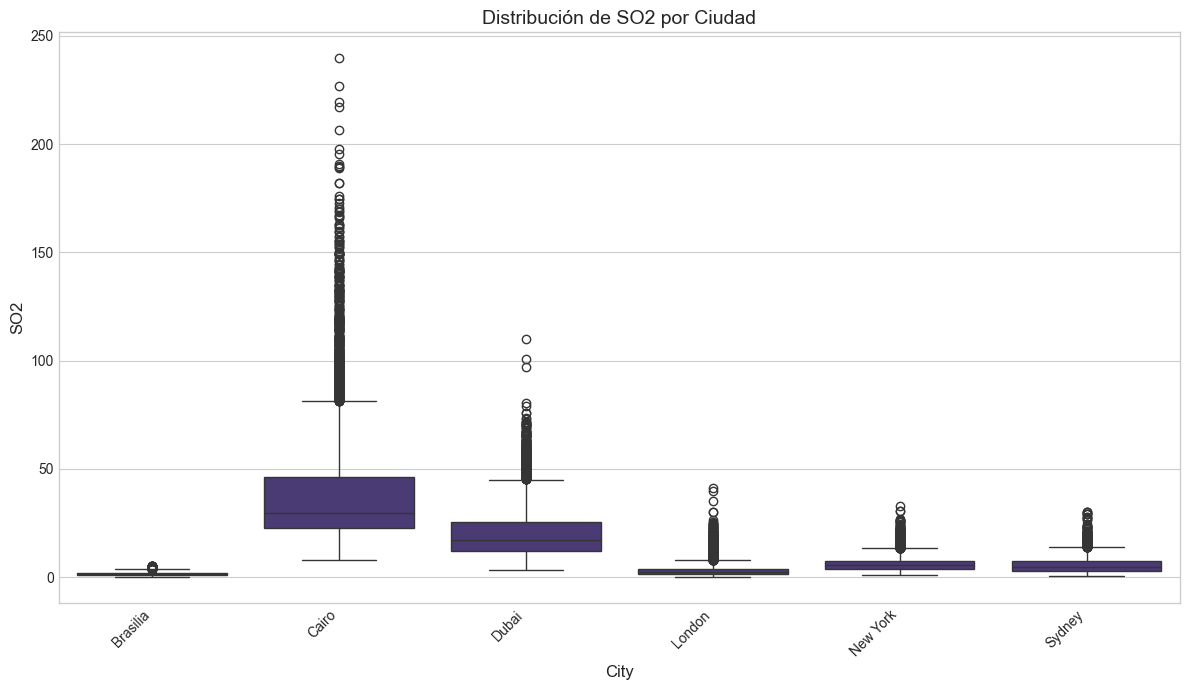

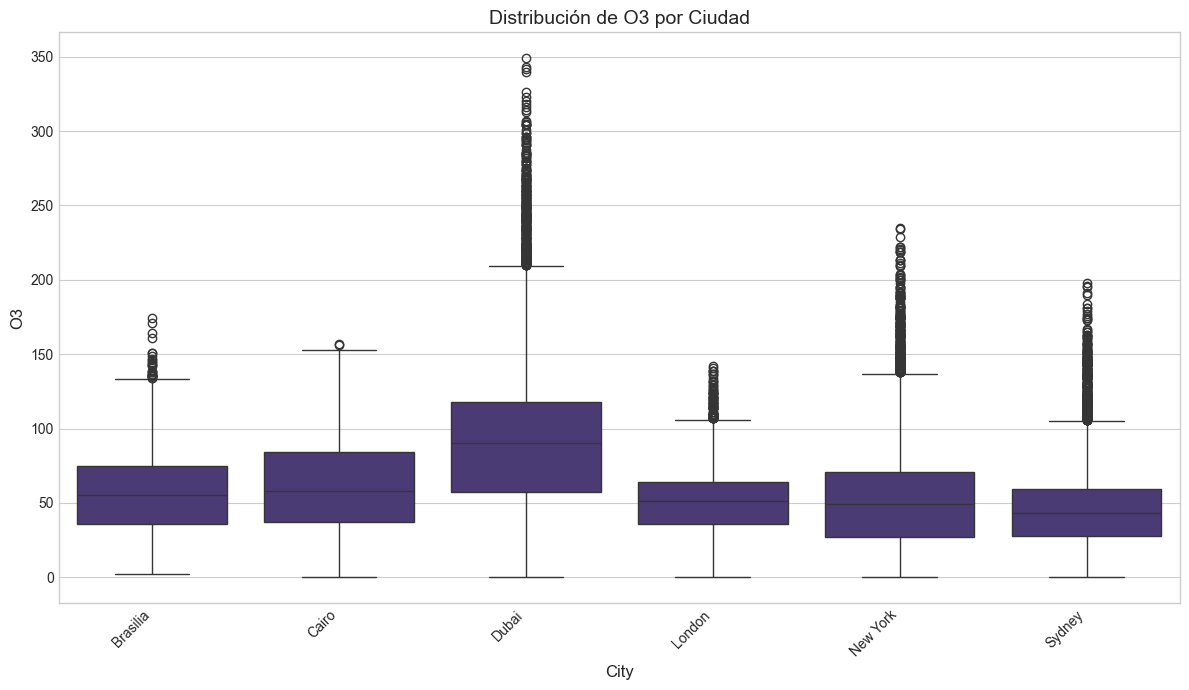

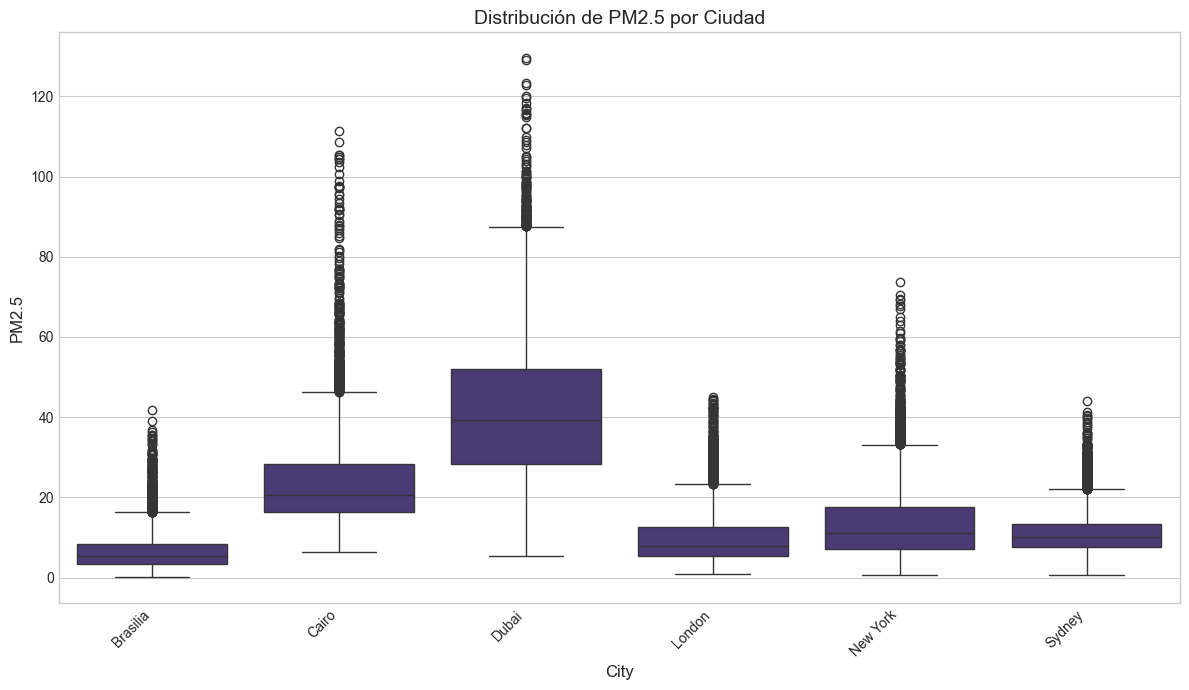

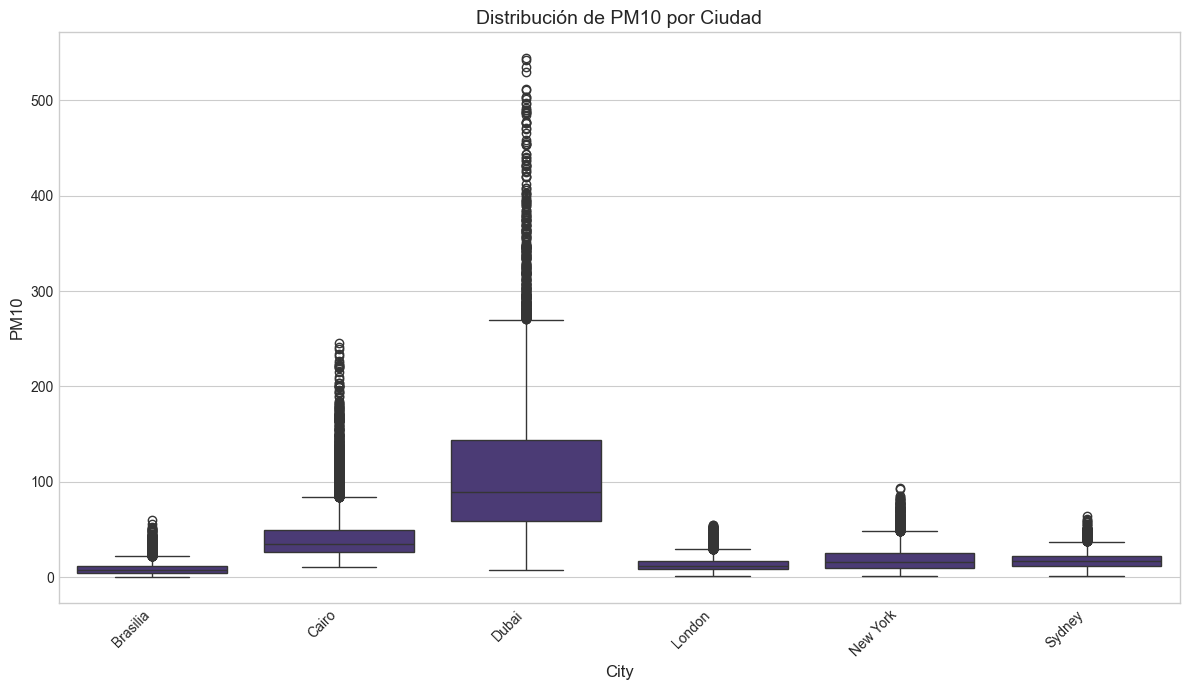

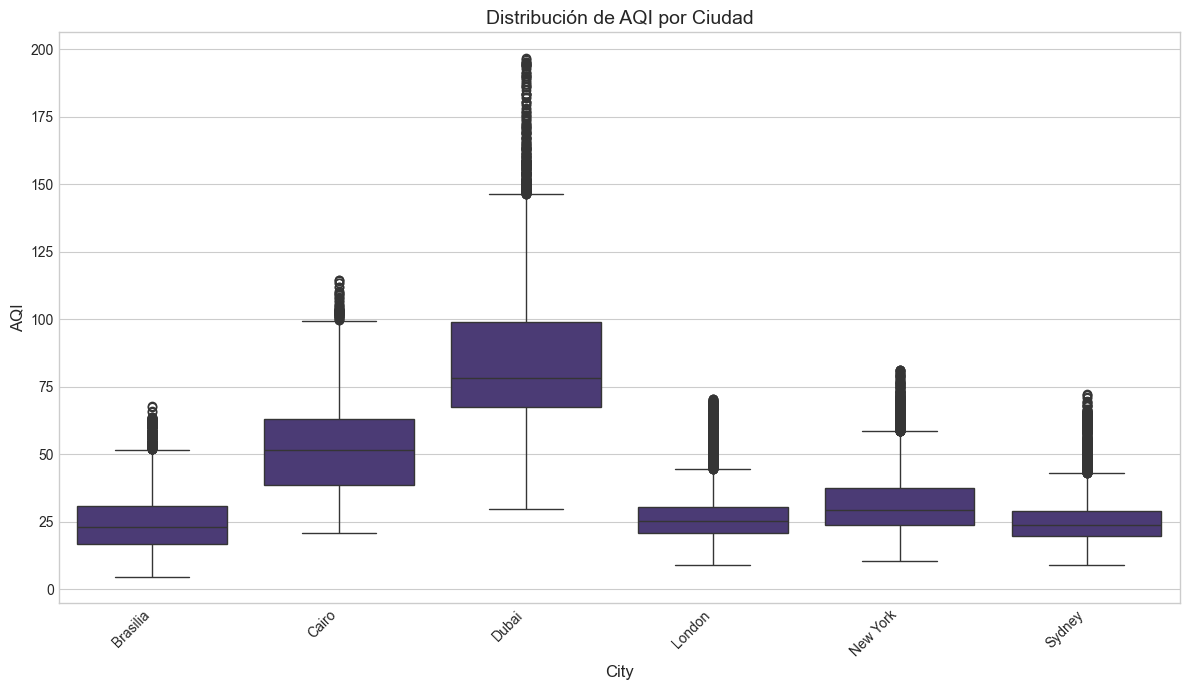

--- Análisis de la Variable Objetivo AQI ---


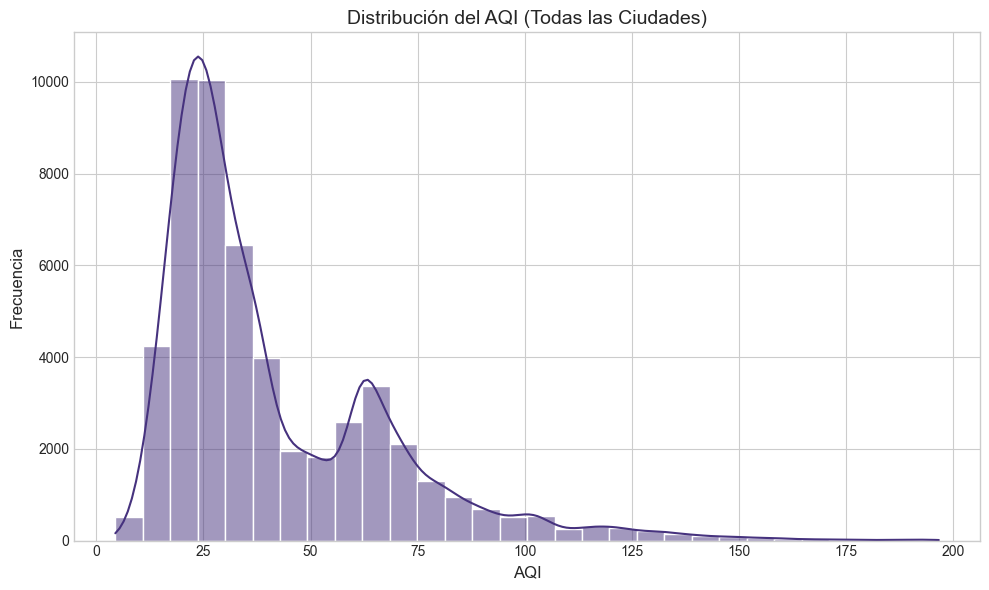

--- Generando Gráficos de Series Temporales de AQI por Ciudad ---


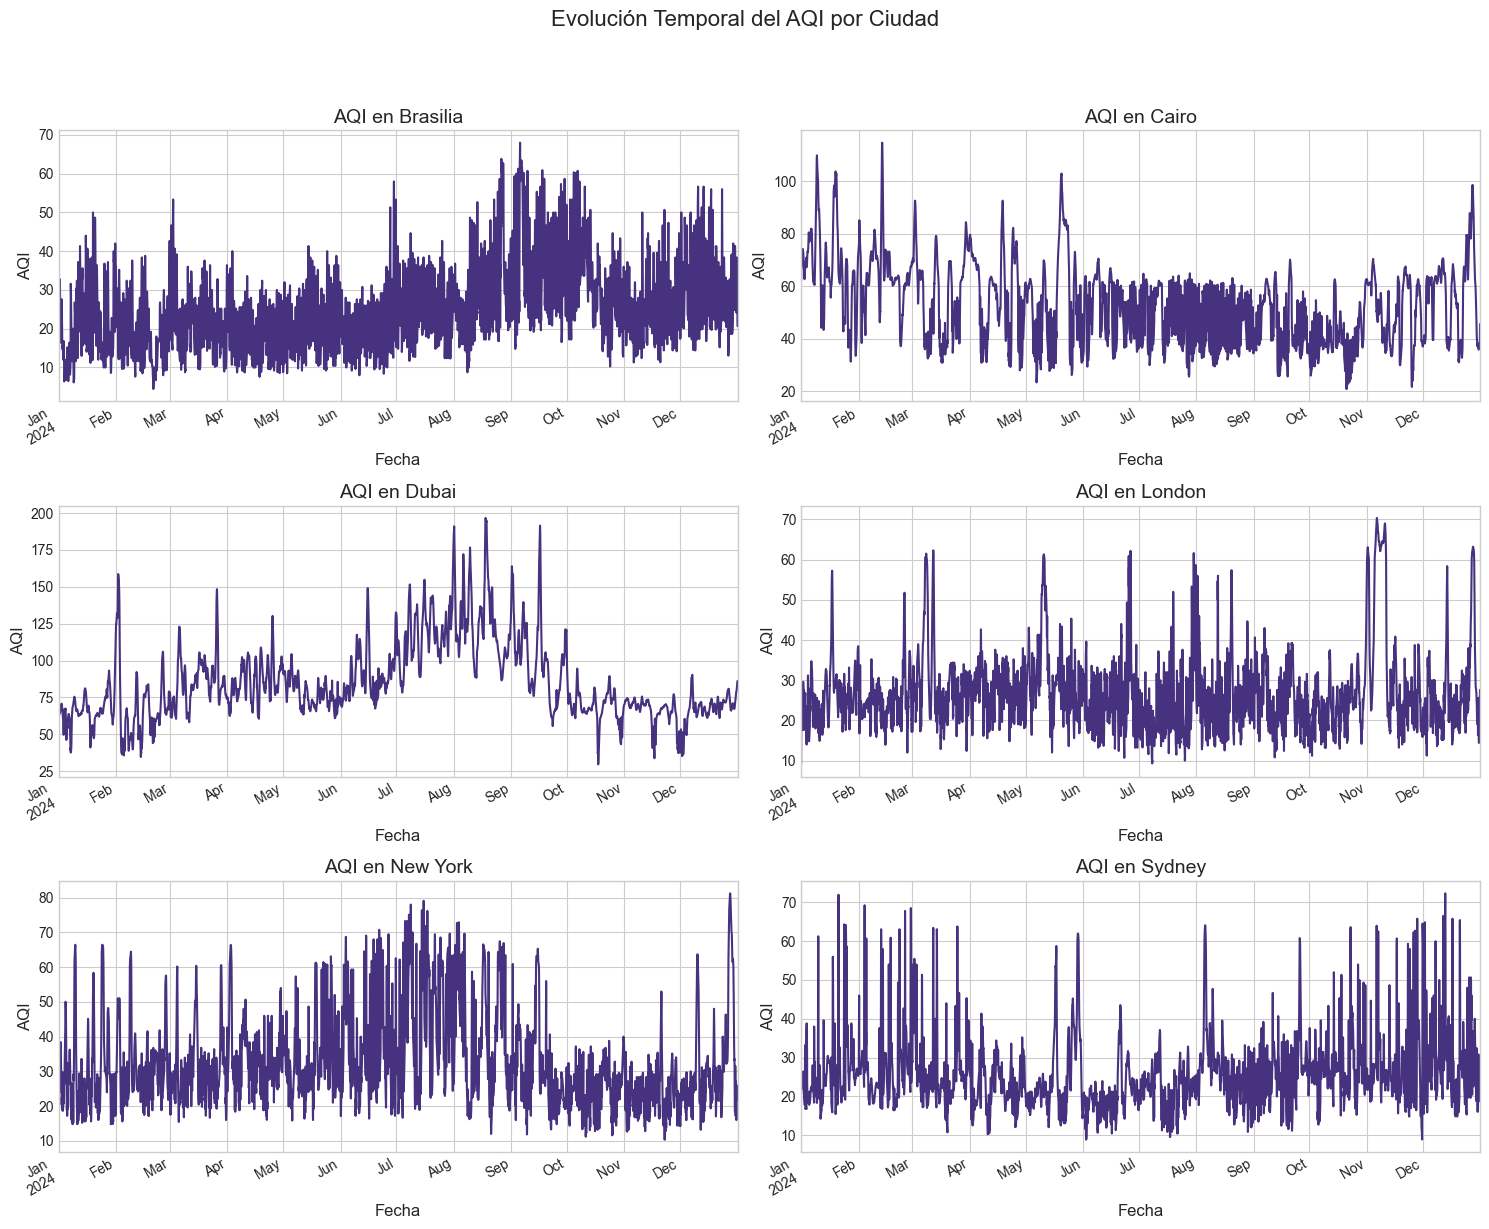

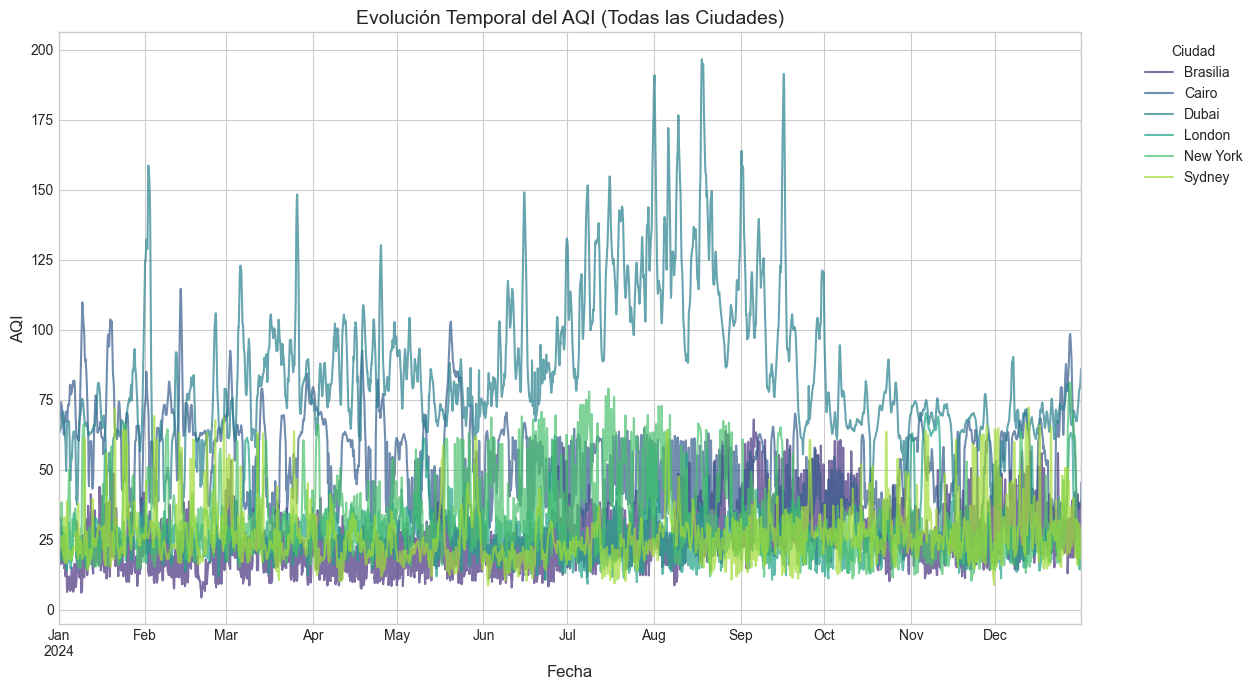

--- Generando Matriz de Correlación (Variables Numéricas) ---


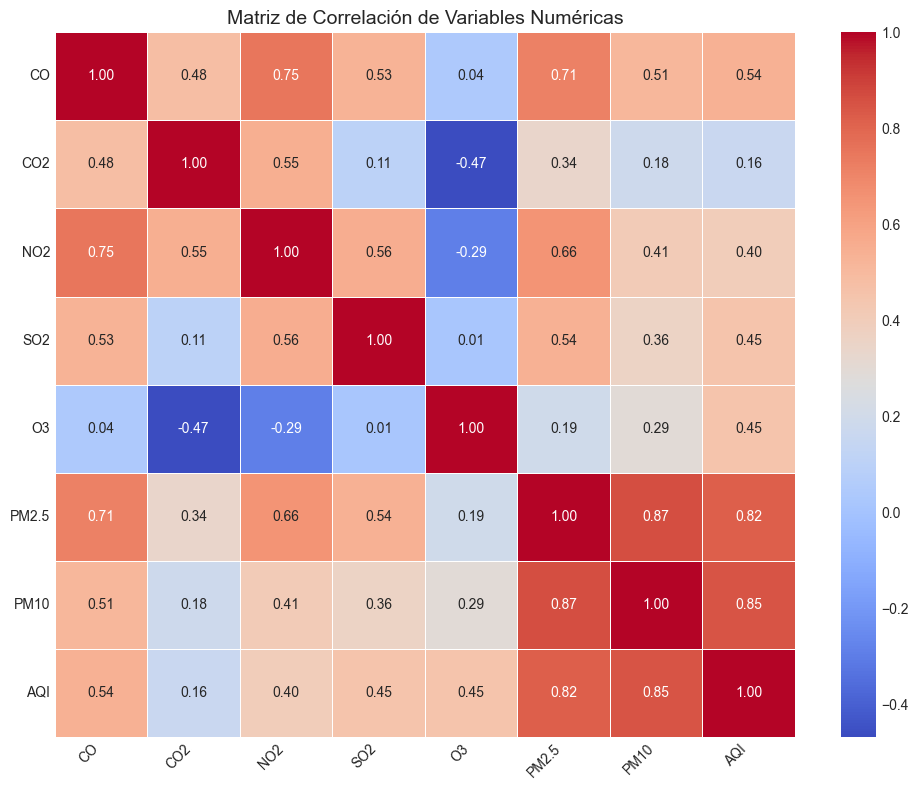


--- Correlación de Variables con AQI ---
AQI      1.000000
PM10     0.845944
PM2.5    0.822101
CO       0.537100
O3       0.452599
SO2      0.451506
NO2      0.403690
CO2      0.157839
Name: AQI, dtype: float64


--- Matriz de Correlación por Ciudad ---


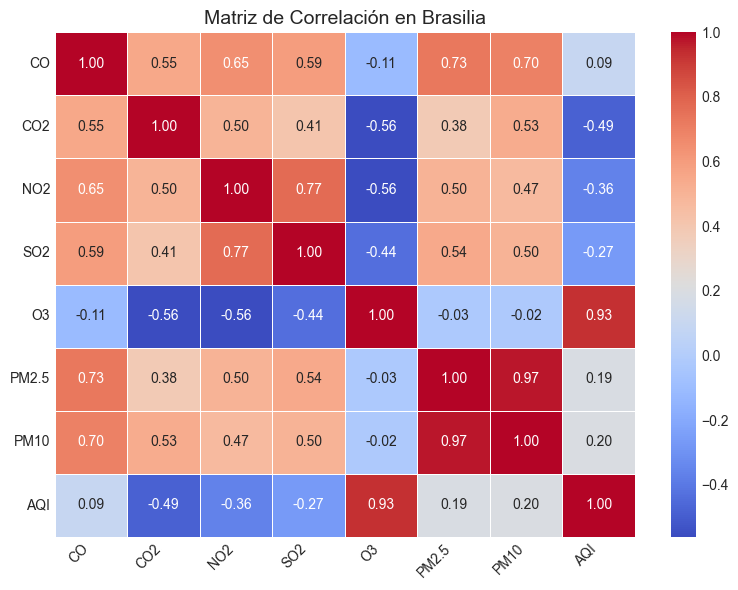

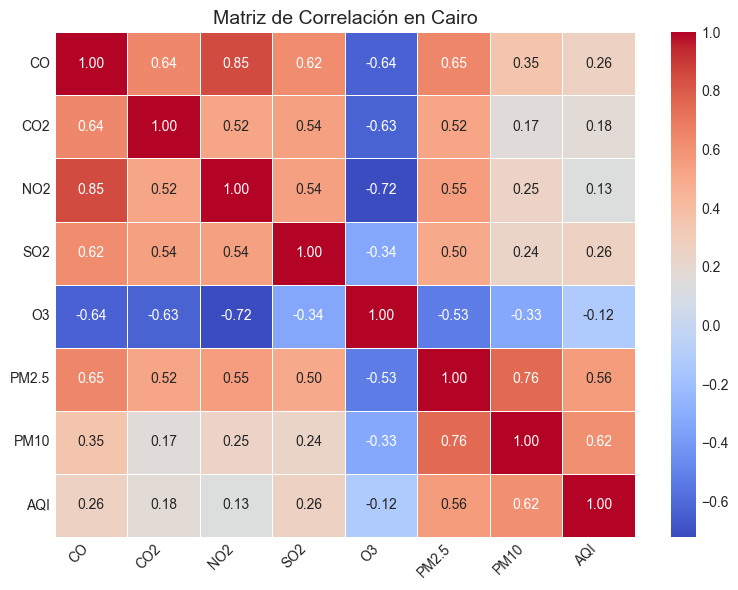

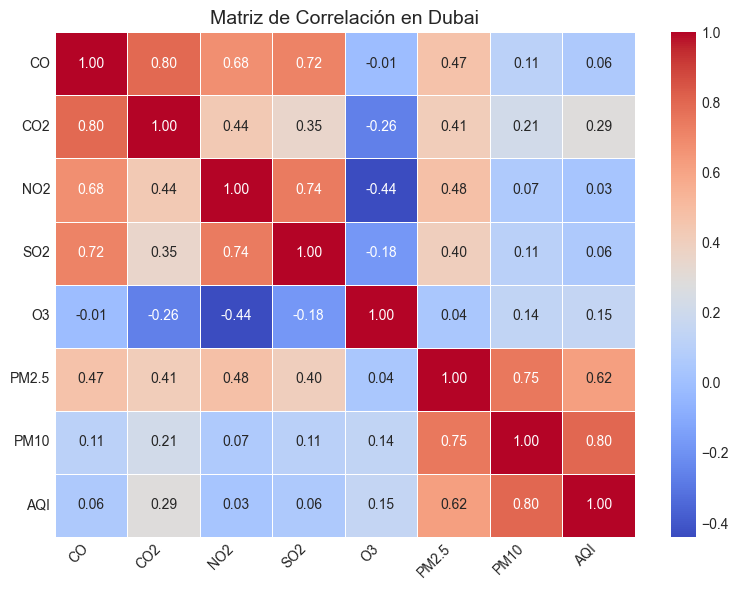

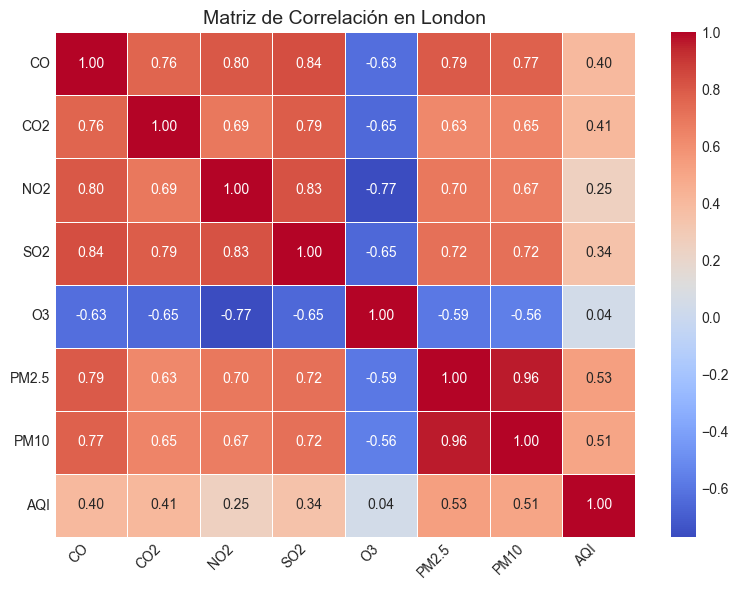

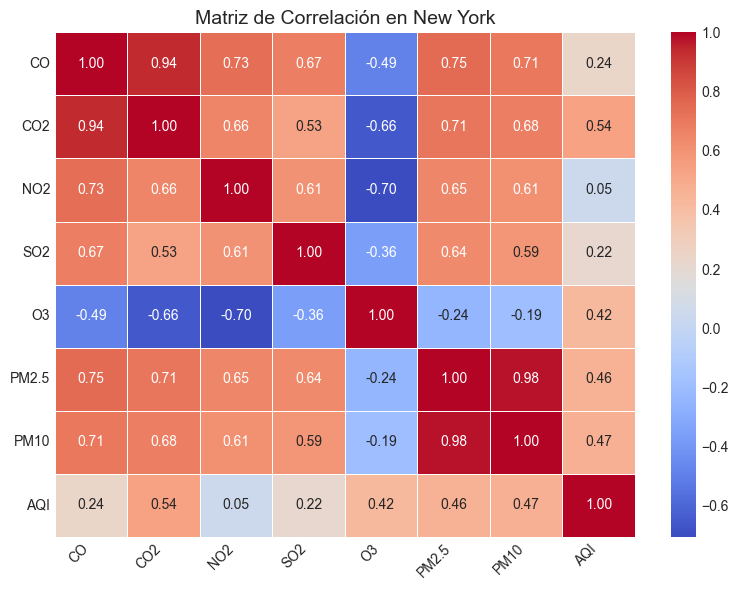

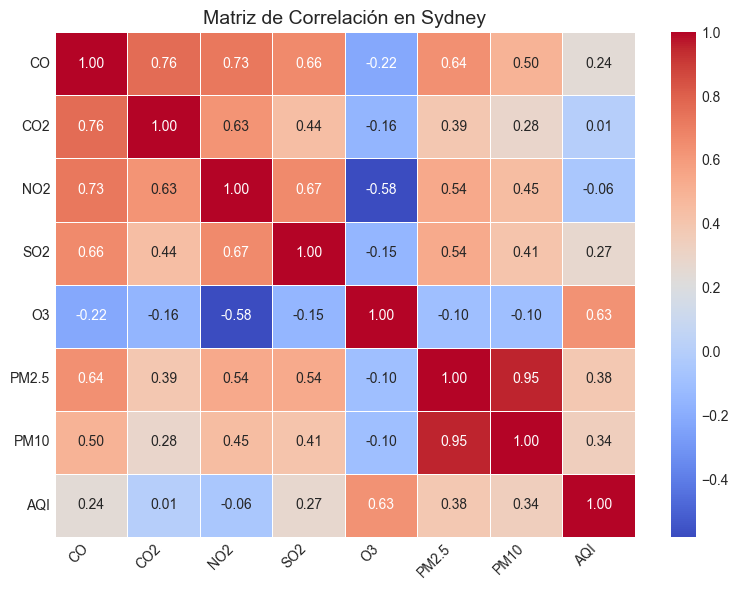

--- Rangos de Fechas por Ciudad ---
Ciudad: Brasilia, Registros: 8784, Desde: 2024-01-01 00:00:00+00:00, Hasta: 2024-12-31 23:00:00+00:00
Ciudad: Cairo, Registros: 8784, Desde: 2024-01-01 00:00:00+00:00, Hasta: 2024-12-31 23:00:00+00:00
Ciudad: Dubai, Registros: 8784, Desde: 2024-01-01 00:00:00+00:00, Hasta: 2024-12-31 23:00:00+00:00
Ciudad: London, Registros: 8784, Desde: 2024-01-01 00:00:00+00:00, Hasta: 2024-12-31 23:00:00+00:00
Ciudad: New York, Registros: 8784, Desde: 2024-01-01 00:00:00+00:00, Hasta: 2024-12-31 23:00:00+00:00
Ciudad: Sydney, Registros: 8784, Desde: 2024-01-01 00:00:00+00:00, Hasta: 2024-12-31 23:00:00+00:00


--- Conteo de Registros por Ciudad ---
City
Brasilia    8784
Cairo       8784
Dubai       8784
London      8784
New York    8784
Sydney      8784
Name: count, dtype: int64


Análisis exploratorio básico completado.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style("whitegrid")
# Configuración para mejorar la visualización de las gráficas
plt.style.use('seaborn-v0_8-whitegrid') # Estilo de gráficas
sns.set_palette("viridis") # Paleta de colores

# --- 1. Carga de Datos ---
# Asegúrate de que la ruta al archivo CSV sea correcta.
# Si el script está en la misma carpeta que la carpeta 'CSVs':
file_path = os.path.join('CSVs', 'Air_Quality.csv')
# Si el script está DENTRO de la carpeta 'CSVs':
# file_path = 'Air_Quality.csv'

try:
    df = pd.read_csv(file_path)
except FileNotFoundError:
    print(f"Error: El archivo '{file_path}' no fue encontrado. Verifica la ruta.")
    exit()

print("--- Primeras filas del DataFrame ---")
print(df.head())
print("\n" + "="*50 + "\n")

# Convertir la columna 'Date' a datetime y manejar errores de zona horaria
# El formato '+00:00' indica UTC. Pandas usualmente lo maneja bien,
# pero si da problemas, podemos hacerlo explícito o quitarlo.
try:
    df['Date'] = pd.to_datetime(df['Date'])
except Exception as e:
    print(f"Error al convertir 'Date': {e}")
    # Intento alternativo si hay problemas con la zona horaria (ej. quitándola)
    # df['Date'] = pd.to_datetime(df['Date'].str.replace(r'[+-]\d{2}:\d{2}$', '', regex=True), errors='coerce')
    # df['Date'] = df['Date'].dt.tz_localize(None) # Si quieres quitar la info de zona horaria

# Establecer 'Date' como índice si es apropiado para análisis de series temporales,
# aunque para algunas visualizaciones es más fácil tenerla como columna.
# Por ahora, la mantenemos como columna para facilitar el agrupamiento por 'City'.

# --- 2. Información Básica y Estadísticas Descriptivas ---
print("--- Información del DataFrame ---")
df.info()
print("\n" + "="*50 + "\n")

print("--- Estadísticas Descriptivas (Variables Numéricas) ---")
# Excluimos 'Date' si aún no es índice y 'City'
numeric_cols = df.select_dtypes(include=['number']).columns
print(df[numeric_cols].describe().T)
print("\n" + "="*50 + "\n")

print("--- Estadísticas Descriptivas de AQI por Ciudad ---")
print(df.groupby('City')['AQI'].describe().T)
print("\n" + "="*50 + "\n")

# --- 3. Análisis de Valores Faltantes ---
print("--- Conteo de Valores Faltantes por Columna ---")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])
print("\n" + "="*50 + "\n")

# Visualización de valores faltantes (heatmap)
plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Mapa de Calor de Valores Faltantes')
plt.tight_layout()
plt.show()

# --- 4. Distribución de las Variables Numéricas ---
# Seleccionar solo columnas numéricas, excluyendo 'Date' y 'City' si es necesario
# (ya lo hicimos con numeric_cols)

# Histogramas
print("--- Generando Histogramas de Variables Numéricas ---")
df[numeric_cols].hist(bins=30, figsize=(15, 10), layout=(-1, 3))
plt.suptitle('Histogramas de Variables Numéricas', y=1.02, size=16)
plt.tight_layout(rect=[0, 0, 1, 0.98]) # Ajuste para el supertítulo
plt.show()

# Boxplots por variable (para ver outliers y distribución general)
print("--- Generando Boxplots de Variables Numéricas ---")
plt.figure(figsize=(18, 10))
for i, col in enumerate(numeric_cols):
    plt.subplot(2, (len(numeric_cols) + 1) // 2, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)
    plt.ylabel('')
plt.suptitle('Boxplots de Variables Numéricas', y=1.02, size=16)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

# Boxplots de cada contaminante y AQI, agrupados por Ciudad
print("--- Generando Boxplots de Variables Numéricas por Ciudad ---")
for col in numeric_cols: # Iteramos sobre todas las numéricas, incluyendo AQI
    if col == 'CO2' and df[col].isnull().all(): # Omitir CO2 si está completamente vacío
        print(f"Omitiendo boxplot para {col} ya que todos sus valores son nulos.")
        continue
    plt.figure(figsize=(12, 7))
    sns.boxplot(x='City', y=col, data=df)
    plt.title(f'Distribución de {col} por Ciudad')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

# --- 5. Análisis Específico de la Variable Objetivo 'AQI' ---
print("--- Análisis de la Variable Objetivo AQI ---")
plt.figure(figsize=(10, 6))
sns.histplot(df['AQI'], kde=True, bins=30)
plt.title('Distribución del AQI (Todas las Ciudades)')
plt.xlabel('AQI')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

# --- 6. Series Temporales de AQI por Ciudad ---
print("--- Generando Gráficos de Series Temporales de AQI por Ciudad ---")
cities = df['City'].unique()
num_cities = len(cities)

# Determinar el layout de subplots
n_cols = 2
n_rows = (num_cities + n_cols - 1) // n_cols

plt.figure(figsize=(15, n_rows * 4))
for i, city in enumerate(cities):
    plt.subplot(n_rows, n_cols, i + 1)
    city_data = df[df['City'] == city].set_index('Date')
    city_data['AQI'].plot(legend=False)
    plt.title(f'AQI en {city}')
    plt.xlabel('Fecha')
    plt.ylabel('AQI')
    plt.xticks(rotation=30, ha='right')
plt.suptitle('Evolución Temporal del AQI por Ciudad', y=1.02, size=16)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

# Plot de AQI de todas las ciudades en una misma gráfica (puede ser denso)
plt.figure(figsize=(15, 7))
for city in cities:
    city_data = df[df['City'] == city].set_index('Date')
    # Usar un rolling mean para suavizar si las series son muy ruidosas
    # city_data['AQI'].rolling(window=24).mean().plot(label=city, alpha=0.8) # Ejemplo con suavizado diario
    city_data['AQI'].plot(label=city, alpha=0.7)
plt.title('Evolución Temporal del AQI (Todas las Ciudades)')
plt.xlabel('Fecha')
plt.ylabel('AQI')
plt.legend(title='Ciudad', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout(rect=[0, 0, 0.85, 1]) # Ajuste para la leyenda fuera
plt.show()


# --- 7. Matriz de Correlación ---
print("--- Generando Matriz de Correlación (Variables Numéricas) ---")
# Seleccionar solo las columnas numéricas para la correlación
correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Matriz de Correlación de Variables Numéricas')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Correlación con AQI específicamente
print("\n--- Correlación de Variables con AQI ---")
corr_with_aqi = correlation_matrix['AQI'].sort_values(ascending=False)
print(corr_with_aqi)
print("\n" + "="*50 + "\n")

# Correlación por ciudad (Iteramos sobre las ciudades)
print("--- Matriz de Correlación por Ciudad ---")
cities = df['City'].unique()
if len(cities) == 0:
    print("No hay ciudades disponibles para analizar.")
else:
    for city in cities:
        city_data = df[df['City'] == city][numeric_cols]
        if city_data.empty:
            print(f"No hay datos disponibles para la ciudad: {city}")
            continue
        city_corr = city_data.corr()
        plt.figure(figsize=(8, 6))
        sns.heatmap(city_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
        plt.title(f'Matriz de Correlación en {city}')
        plt.xticks(rotation=45, ha='right')
        plt.yticks(rotation=0)
        plt.tight_layout()
        plt.show()

# --- 8. Información adicional sobre los datos ---
print("--- Rangos de Fechas por Ciudad ---")
for city in cities:
    city_data = df[df['City'] == city]
    min_date = city_data['Date'].min()
    max_date = city_data['Date'].max()
    count = len(city_data)
    print(f"Ciudad: {city}, Registros: {count}, Desde: {min_date}, Hasta: {max_date}")
print("\n" + "="*50 + "\n")

print("--- Conteo de Registros por Ciudad ---")
print(df['City'].value_counts())
print("\n" + "="*50 + "\n")

print("Análisis exploratorio básico completado.")

Columna 'CO2' descartada.

--- DataFrame con nuevas características temporales (primeras filas) ---
                       Date      City     CO   NO2  SO2    O3  PM2.5  PM10  \
0 2024-01-01 00:00:00+00:00  Brasilia  323.0  23.8  2.8  42.0   12.0  17.1   
1 2024-01-01 01:00:00+00:00  Brasilia  318.0  21.9  2.7  40.0   12.5  17.9   
2 2024-01-01 02:00:00+00:00  Brasilia  309.0  19.2  2.6  39.0   12.1  17.3   
3 2024-01-01 03:00:00+00:00  Brasilia  295.0  16.3  2.4  38.0   11.4  16.2   
4 2024-01-01 04:00:00+00:00  Brasilia  270.0  13.0  2.1  40.0   10.2  14.6   

         AQI  Year  Month  DayOfWeek  Hour  IsWeekend  
0  16.800000  2024      1          0     0      False  
1  16.000000  2024      1          0     1      False  
2  15.599999  2024      1          0     2      False  
3  15.200000  2024      1          0     3      False  
4  16.000000  2024      1          0     4      False  


--- Análisis de Comportamiento Semanal y Laborable/Fin de Semana ---

--- Análisis para la Ci

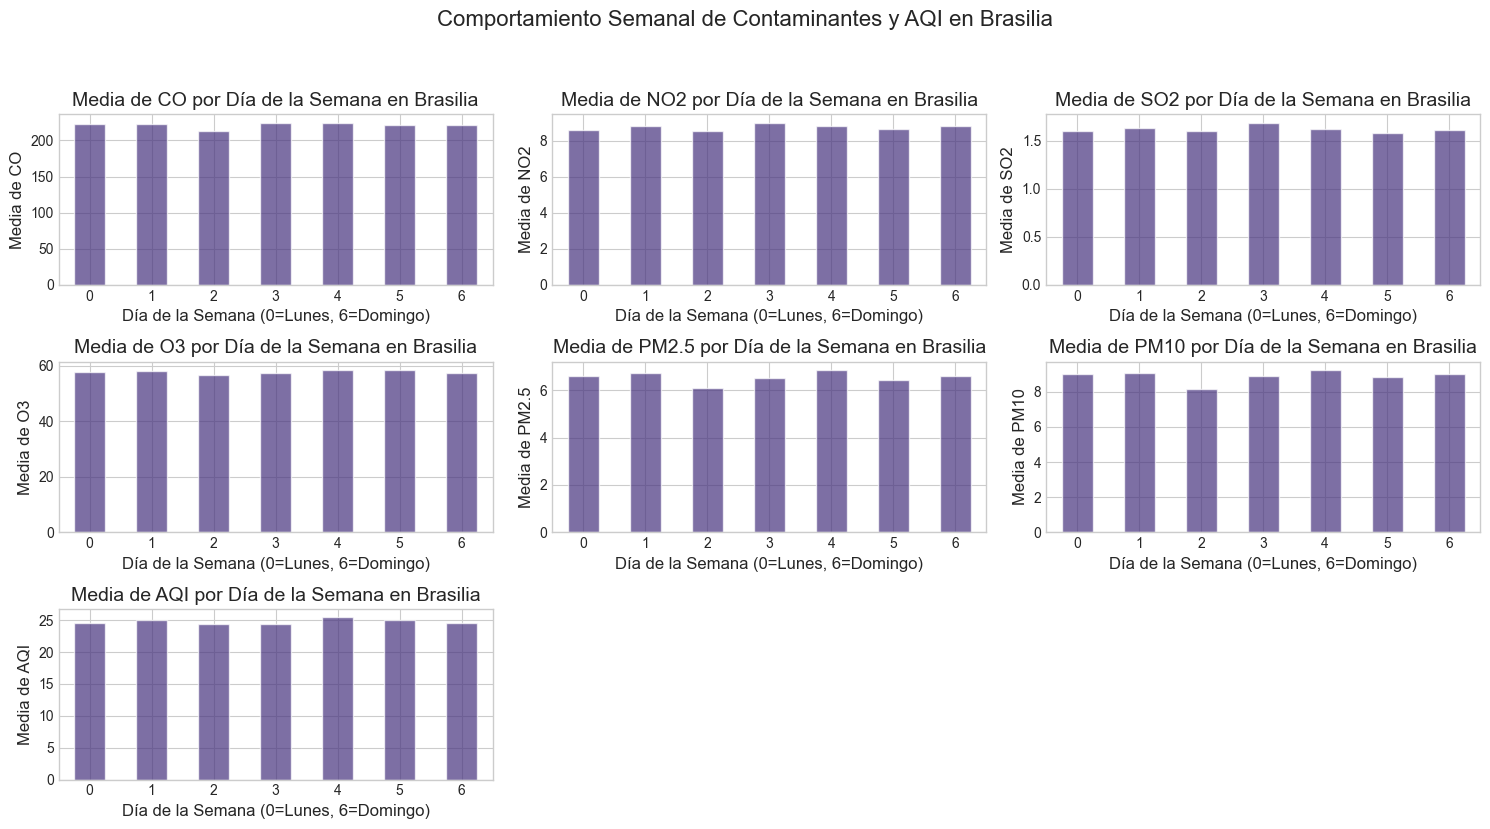

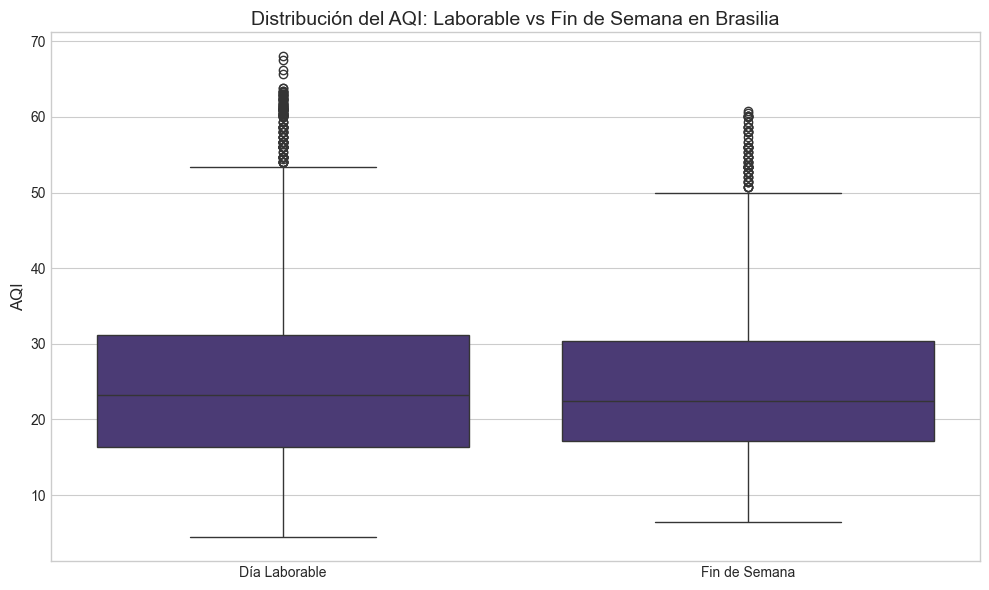


--- Análisis para la Ciudad: Cairo ---


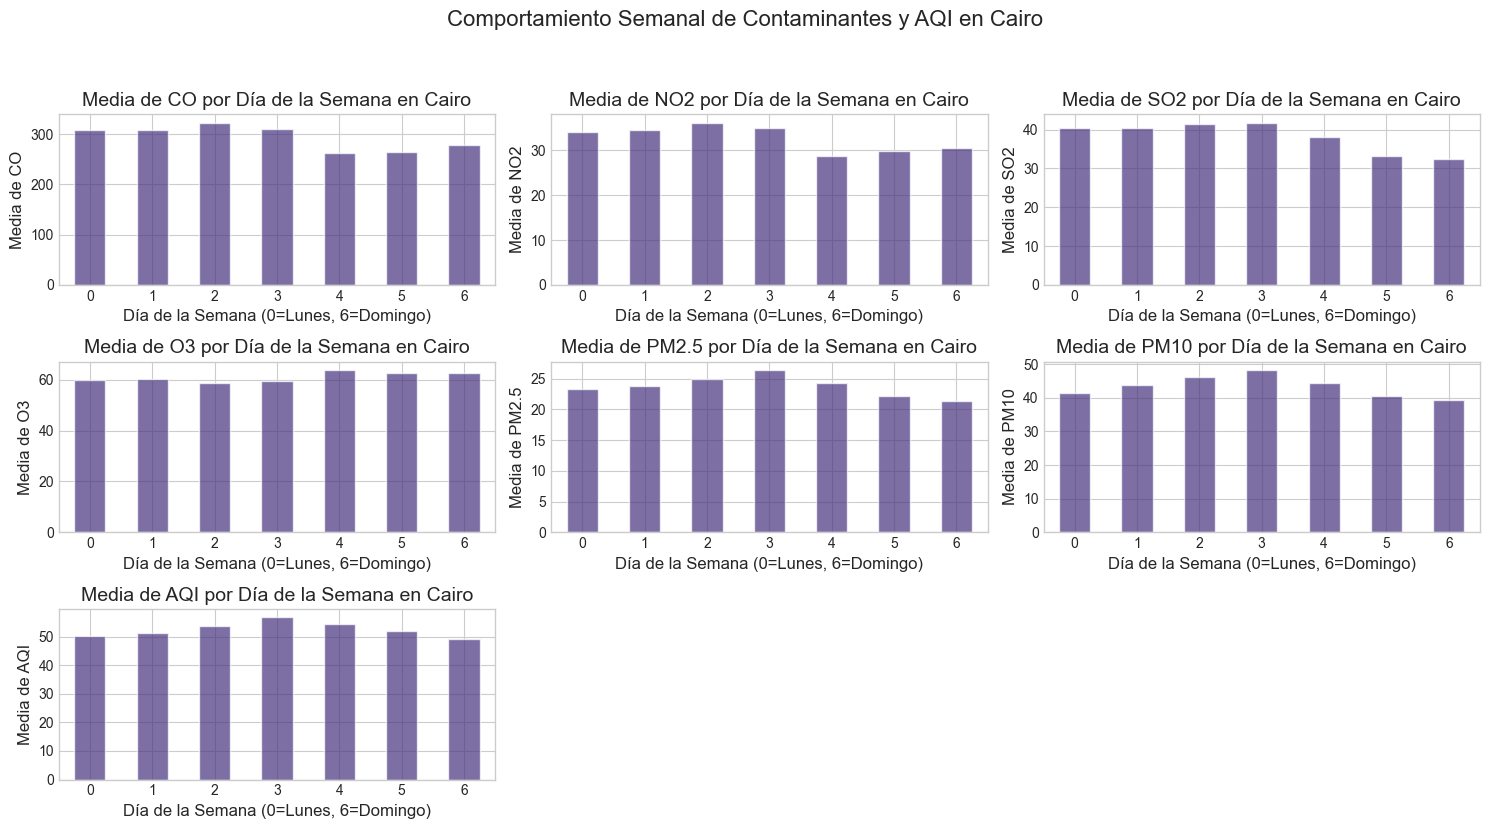

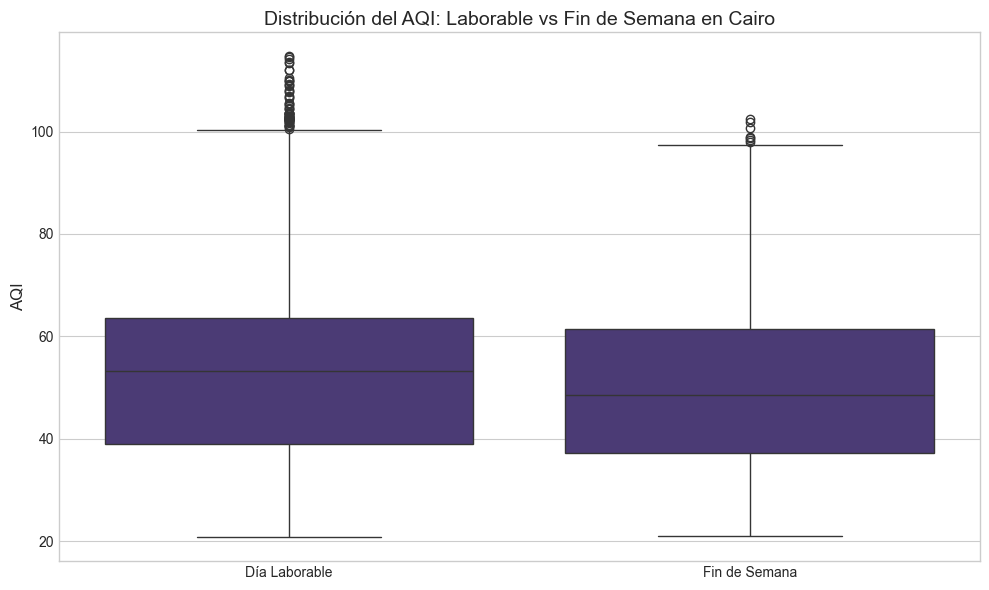


--- Análisis para la Ciudad: Dubai ---


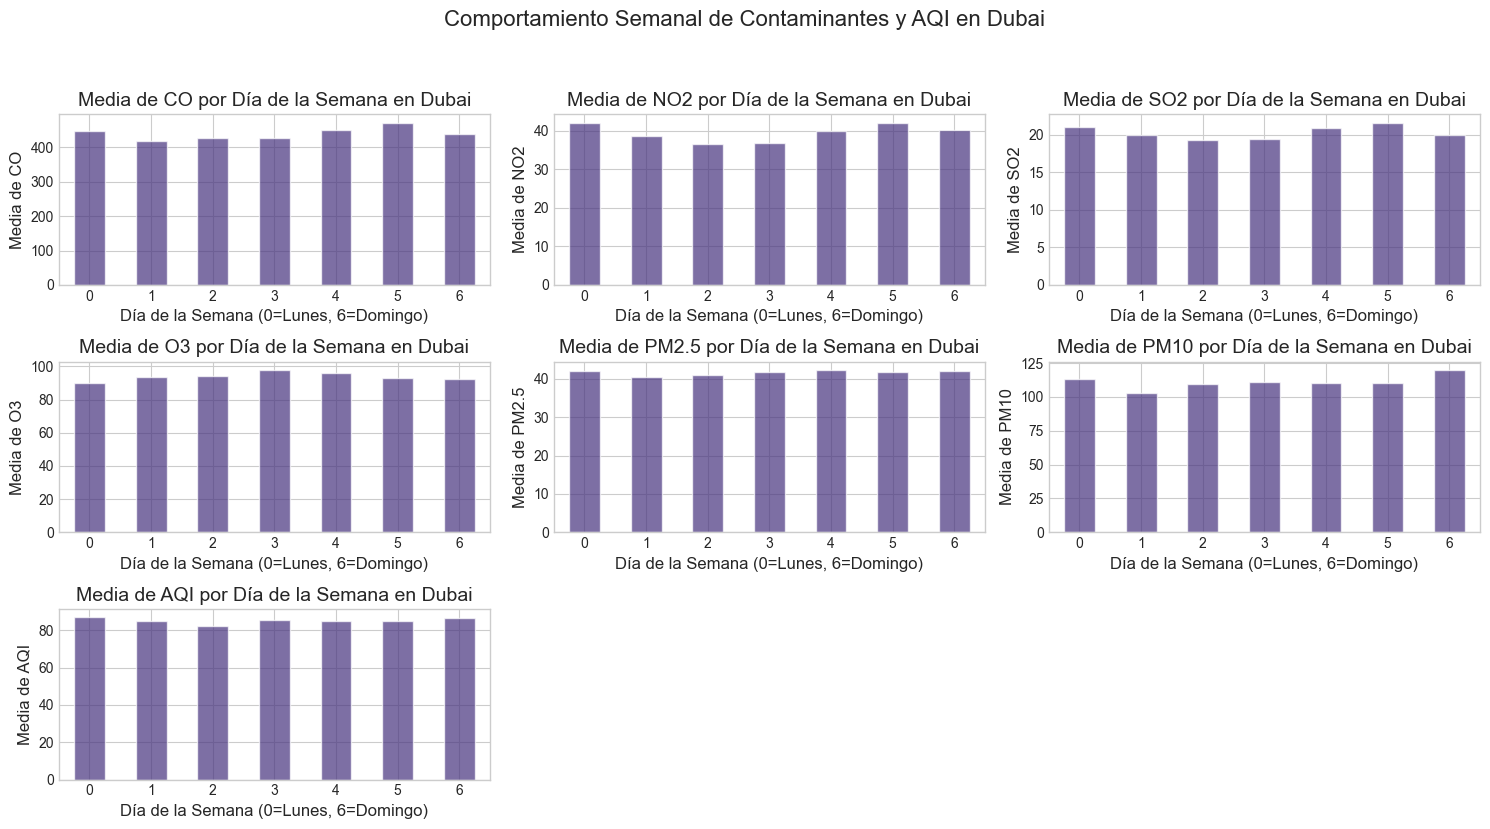

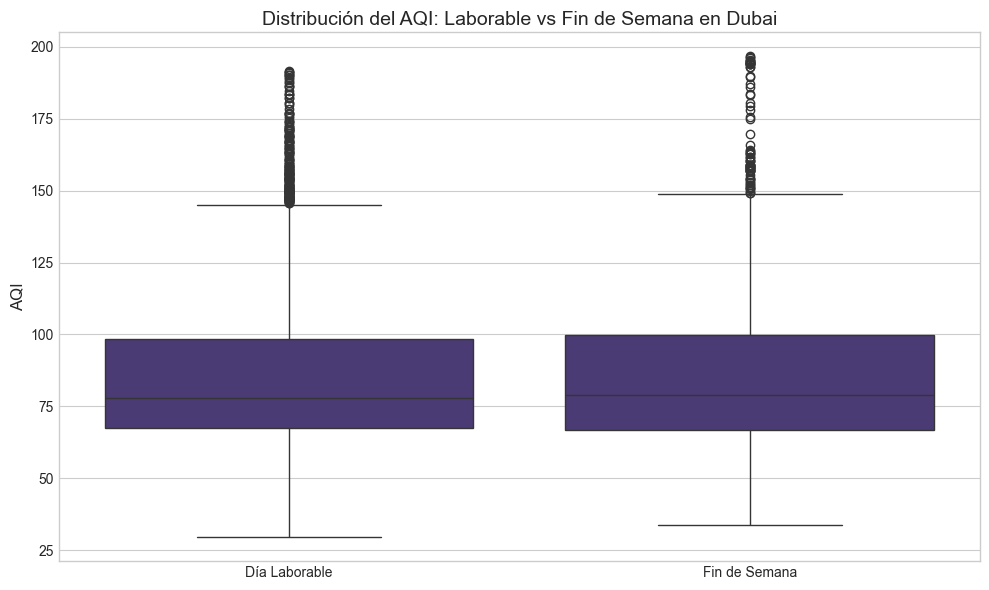


--- Análisis para la Ciudad: London ---


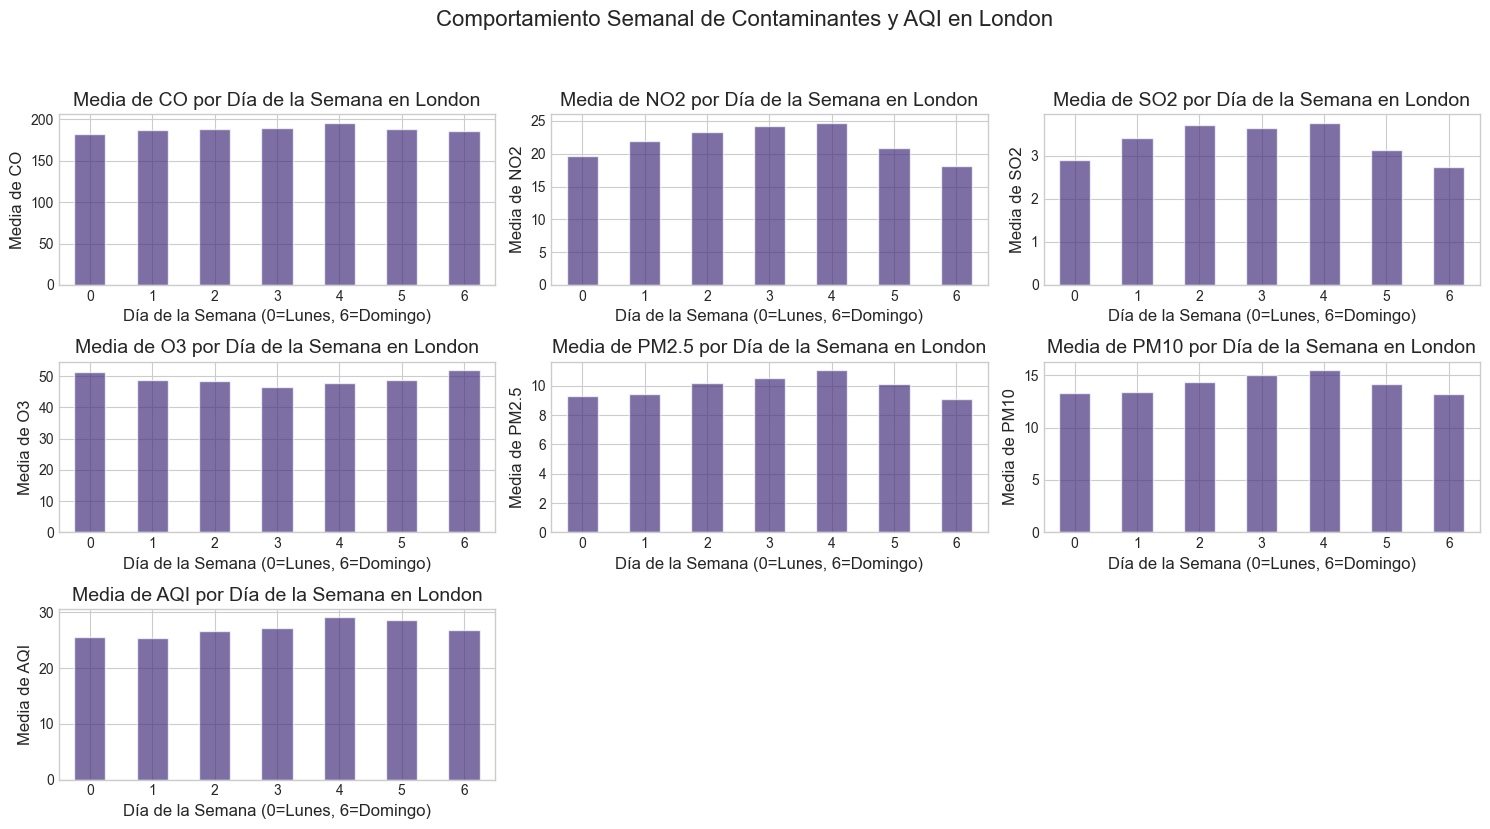

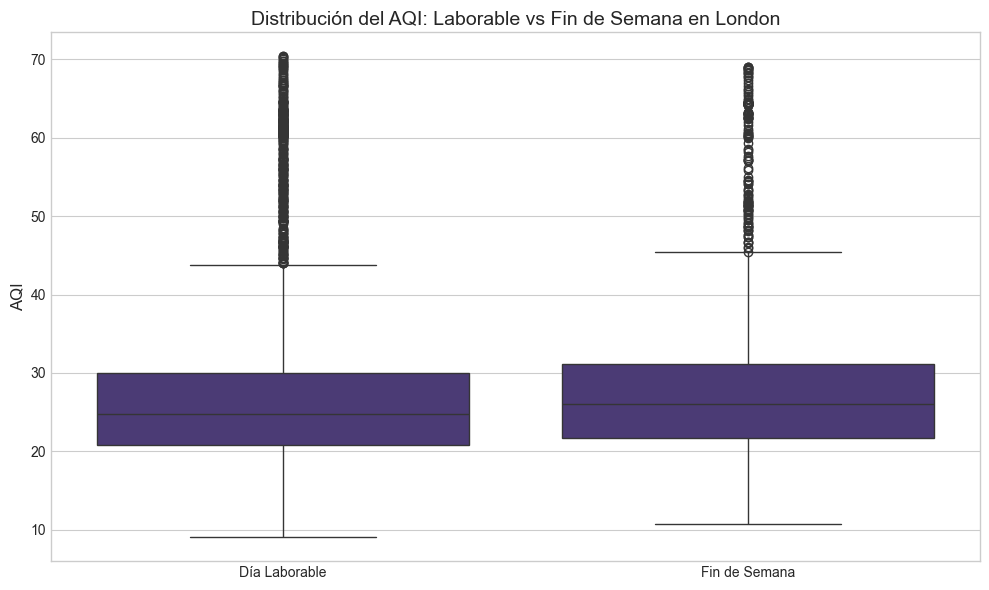


--- Análisis para la Ciudad: New York ---


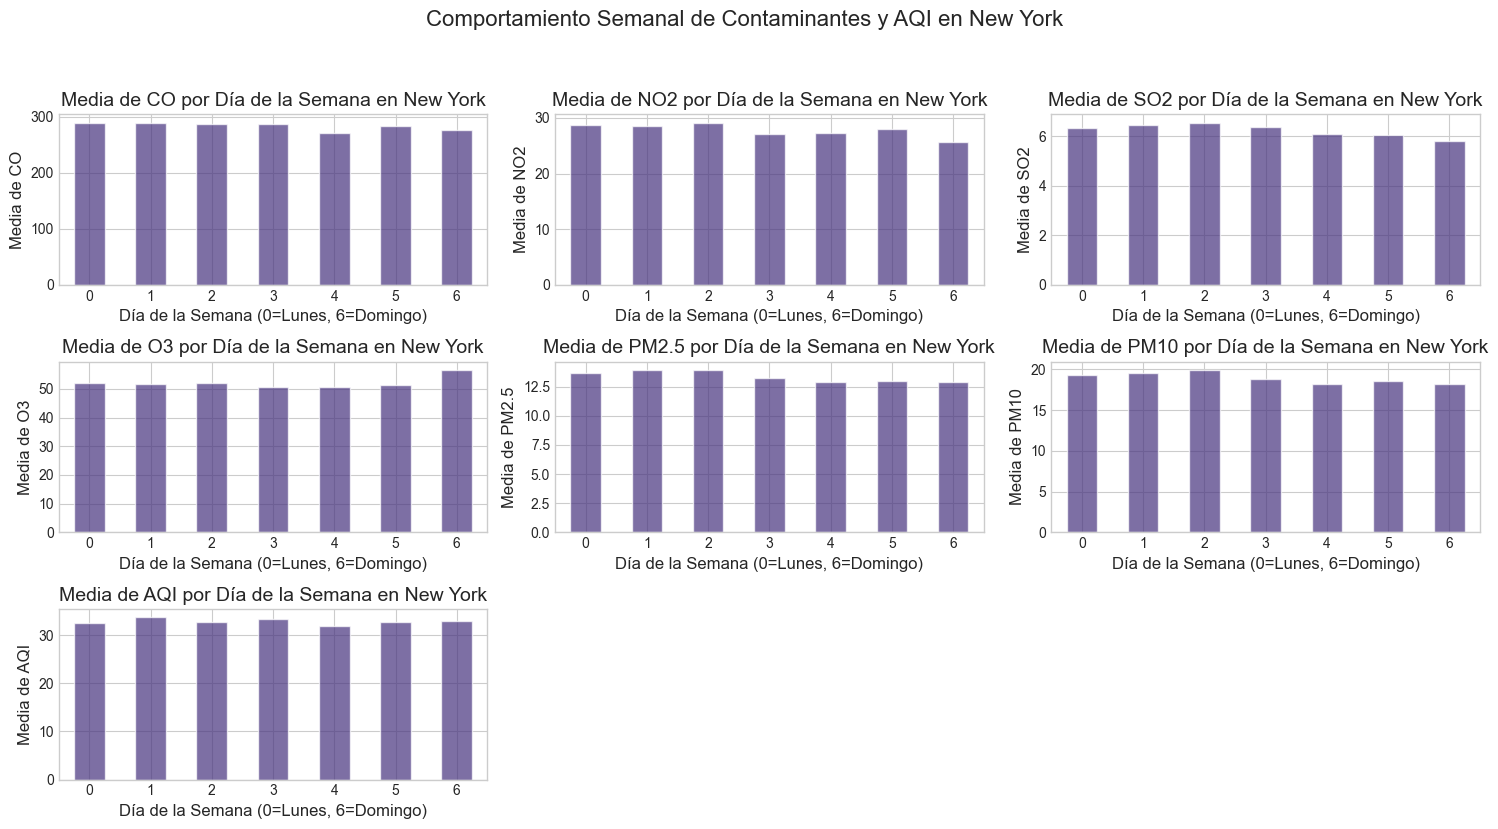

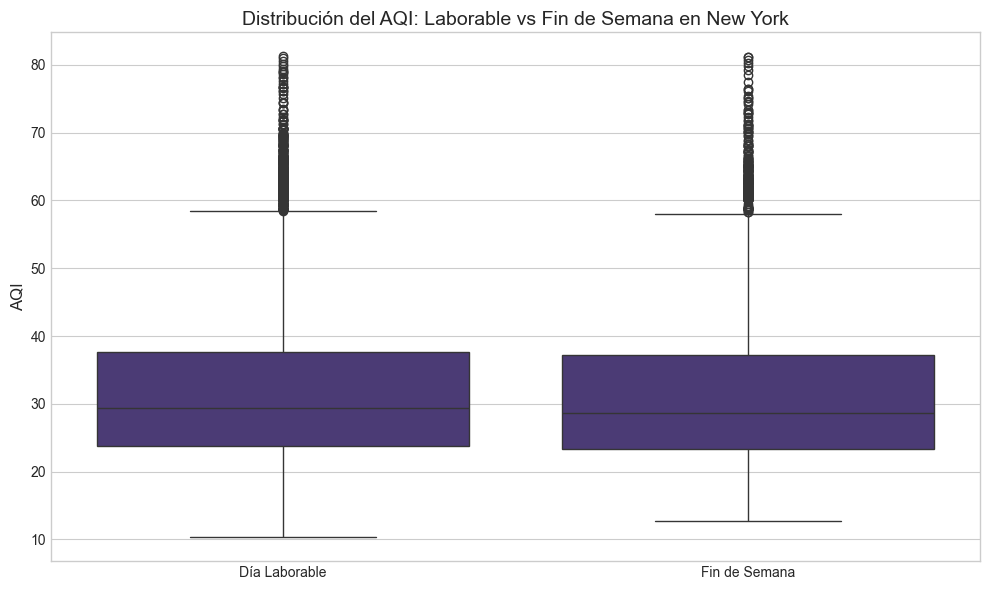


--- Análisis para la Ciudad: Sydney ---


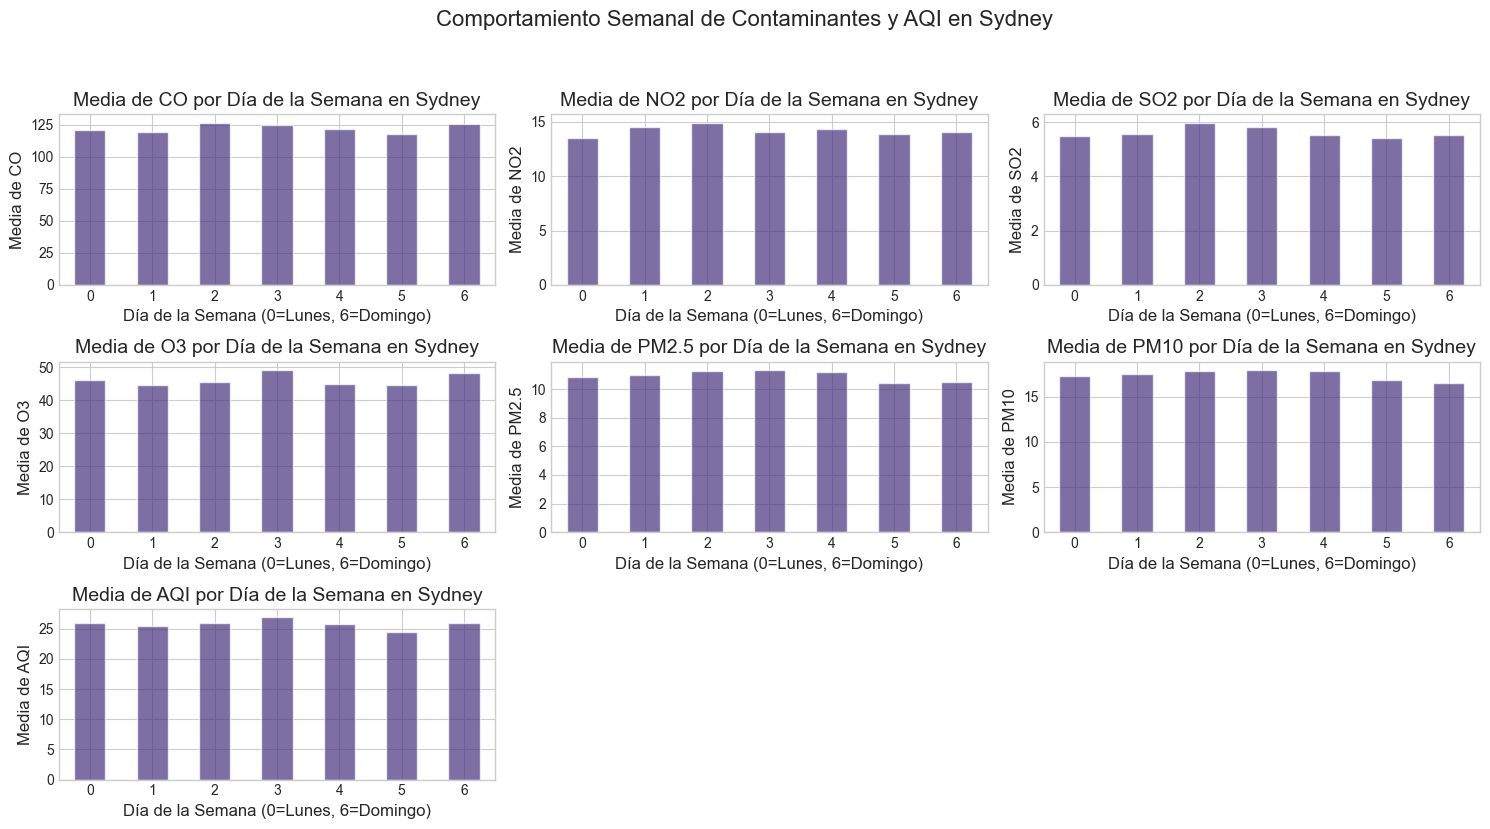

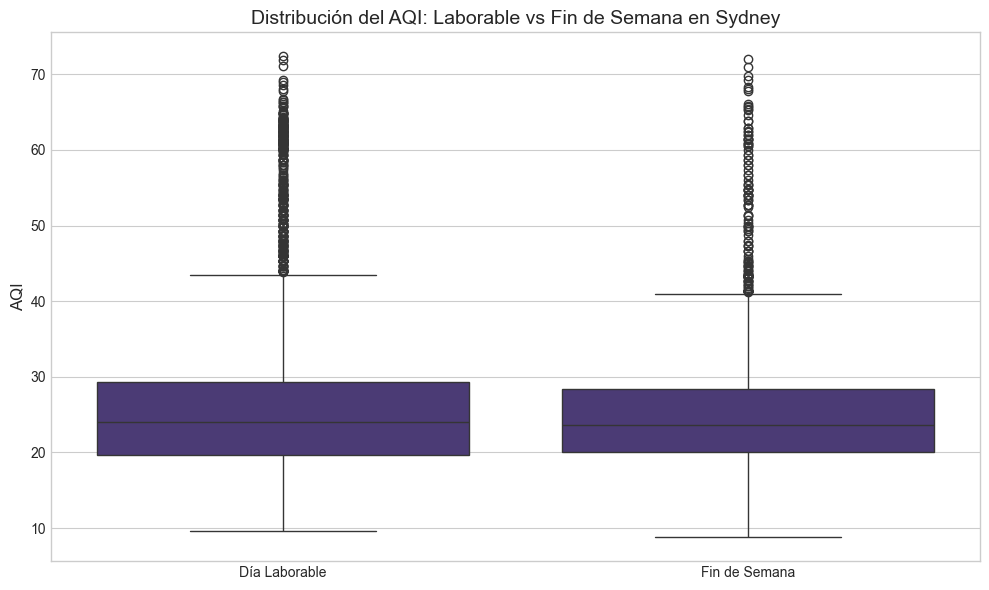


--- Análisis de Autocorrelación (ACF y PACF) para AQI por Ciudad ---

--- ACF/PACF para AQI en: Brasilia ---


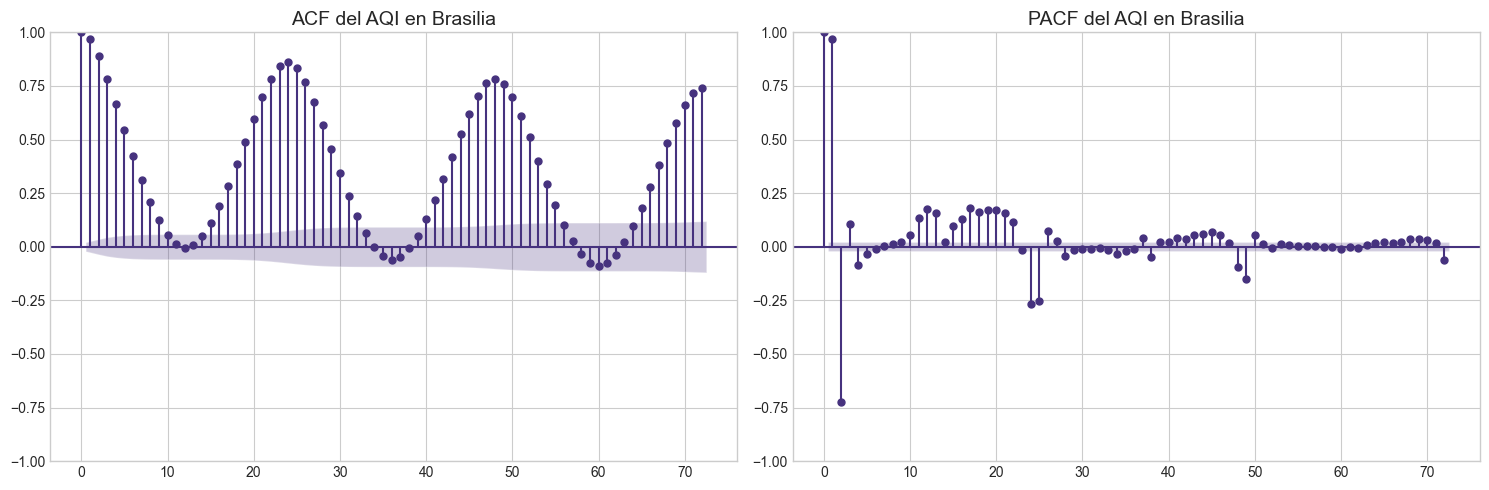


--- ACF/PACF para AQI en: Cairo ---


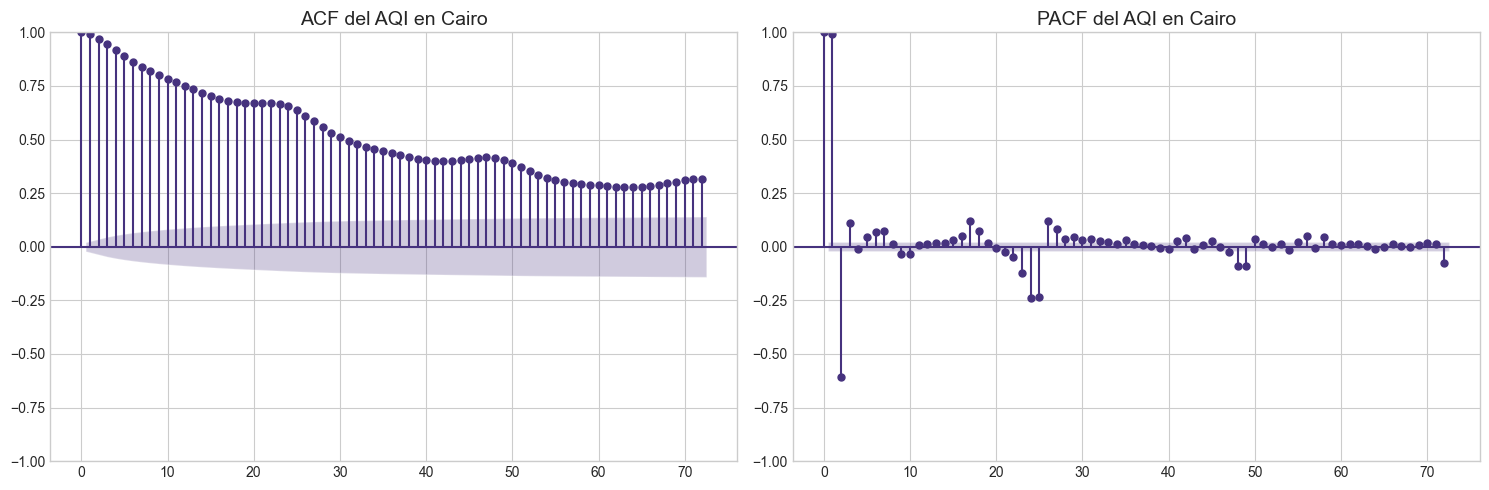


--- ACF/PACF para AQI en: Dubai ---


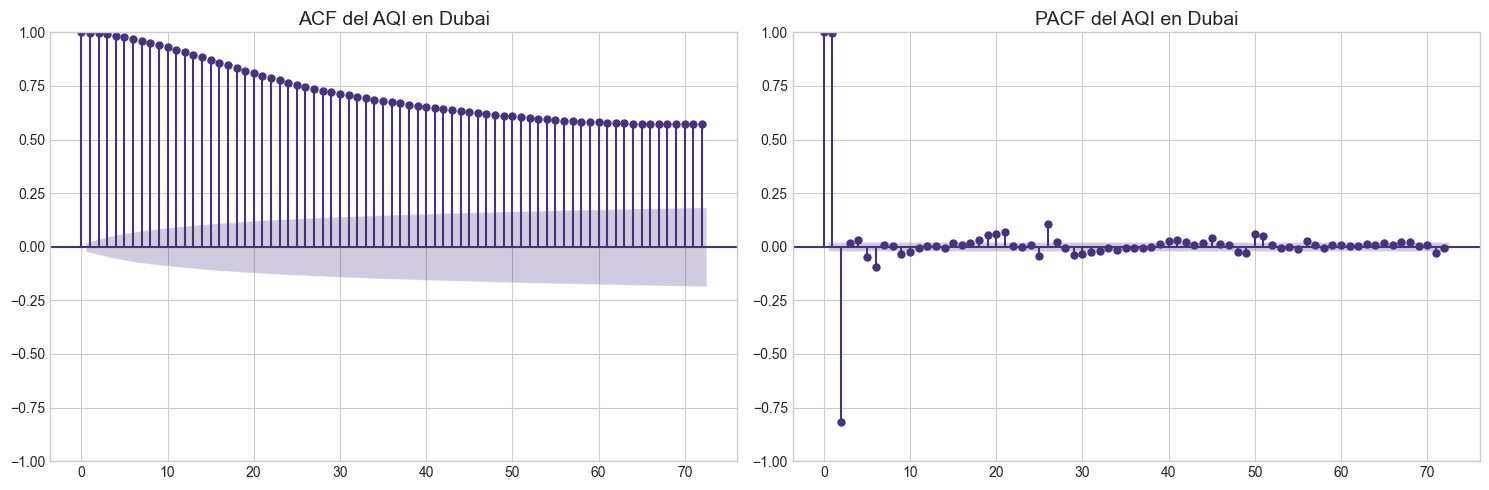


--- ACF/PACF para AQI en: London ---


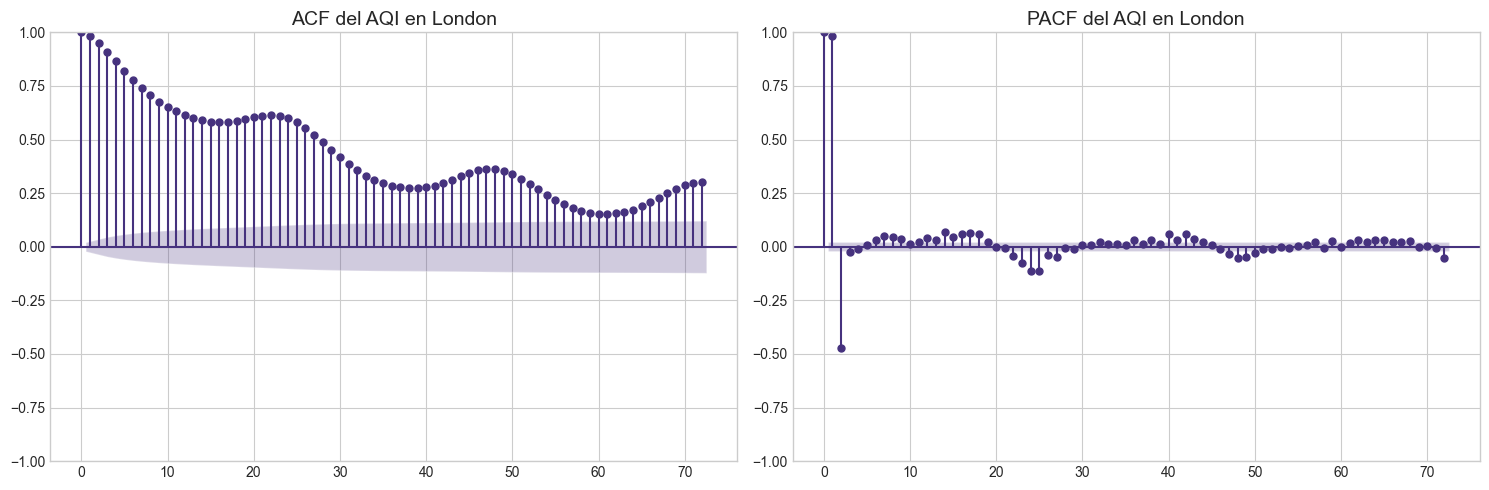


--- ACF/PACF para AQI en: New York ---


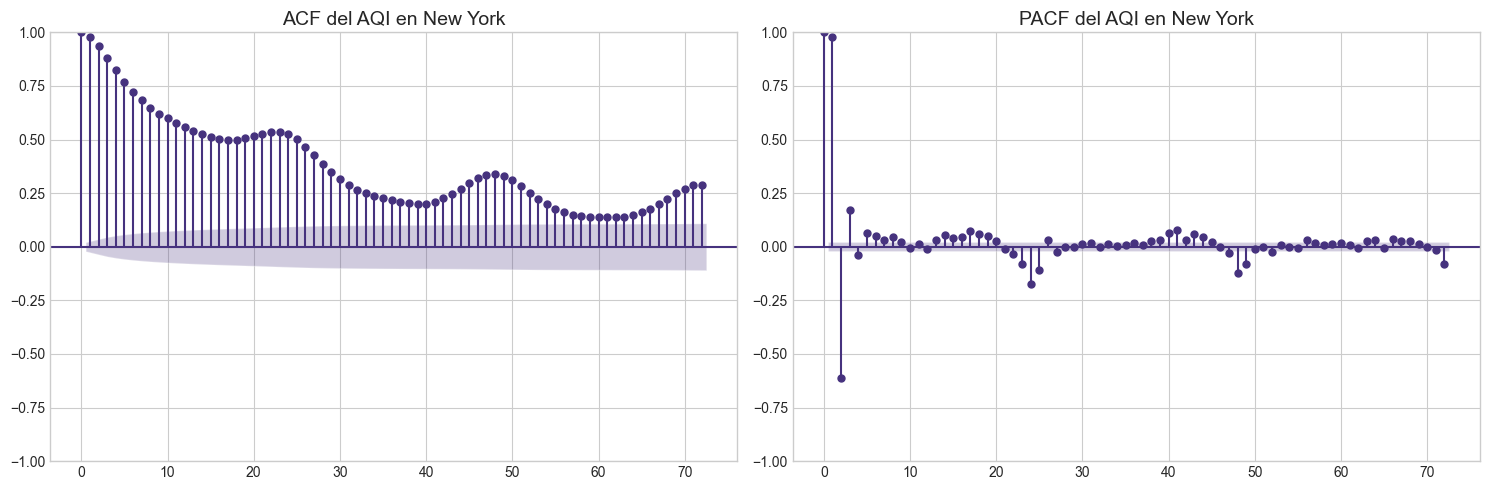


--- ACF/PACF para AQI en: Sydney ---


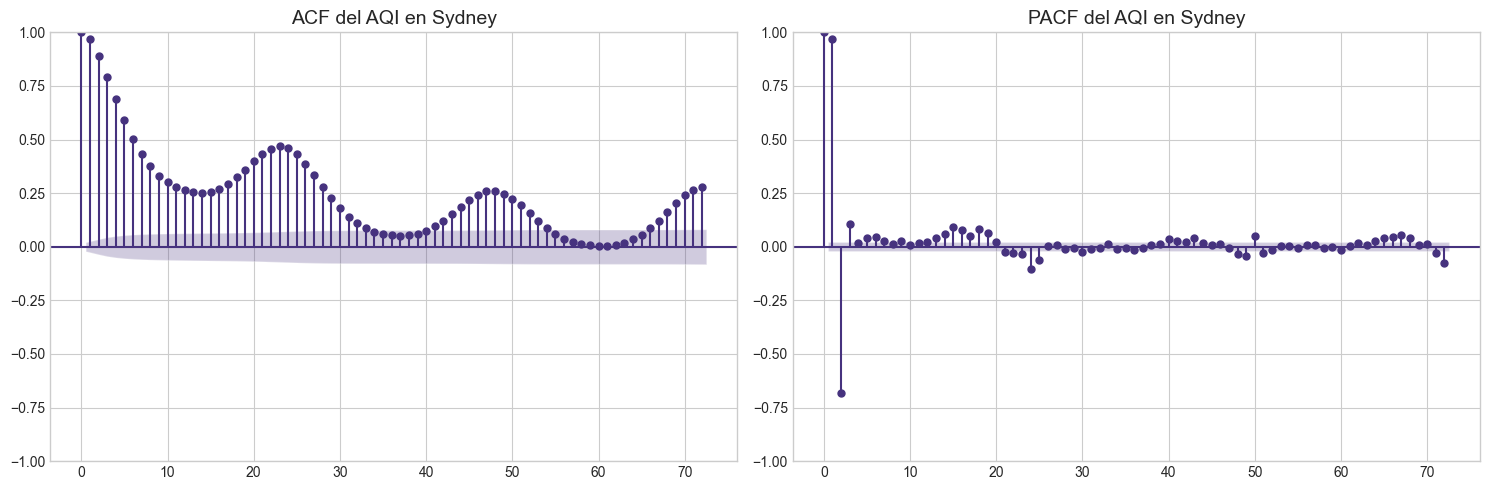


--- Test de Estacionariedad (Dickey-Fuller Aumentado) para AQI por Ciudad ---
Resultados del Test de Dickey-Fuller Aumentado para AQI en Brasilia:
Test Statistic                -6.390174e+00
p-value                        2.115484e-08
#Lags Used                     3.700000e+01
Number of Observations Used    8.746000e+03
Critical Value (1%)           -3.431098e+00
Critical Value (5%)           -2.861871e+00
Critical Value (10%)          -2.566946e+00
dtype: float64
=> Conclusión: La serie es probablemente estacionaria (se rechaza la hipótesis nula H0)
------------------------------
Resultados del Test de Dickey-Fuller Aumentado para AQI en Cairo:
Test Statistic                -7.865410e+00
p-value                        5.150609e-12
#Lags Used                     3.400000e+01
Number of Observations Used    8.749000e+03
Critical Value (1%)           -3.431098e+00
Critical Value (5%)           -2.861870e+00
Critical Value (10%)          -2.566946e+00
dtype: float64
=> Conclusión: La ser

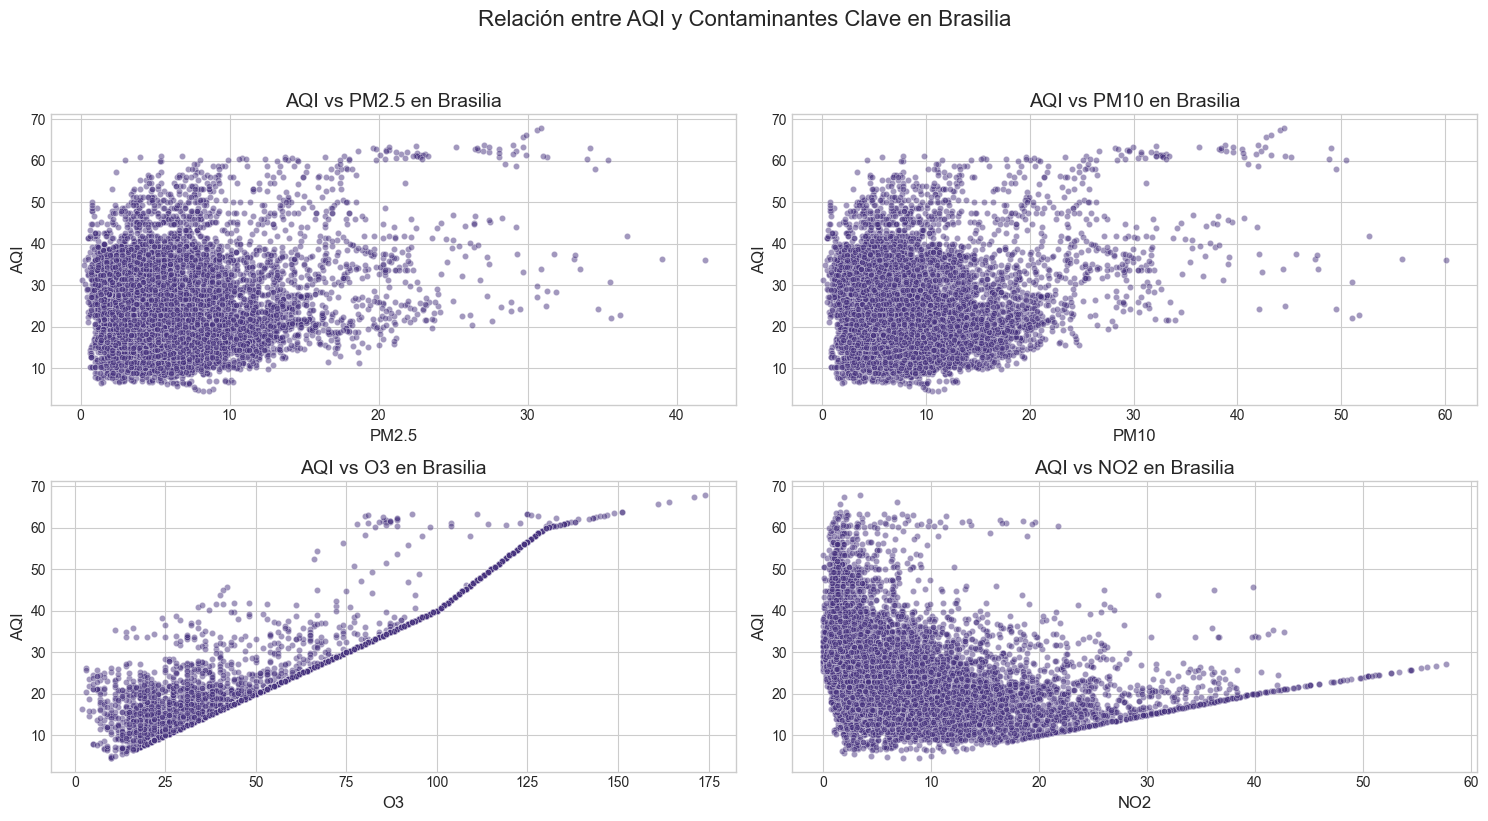

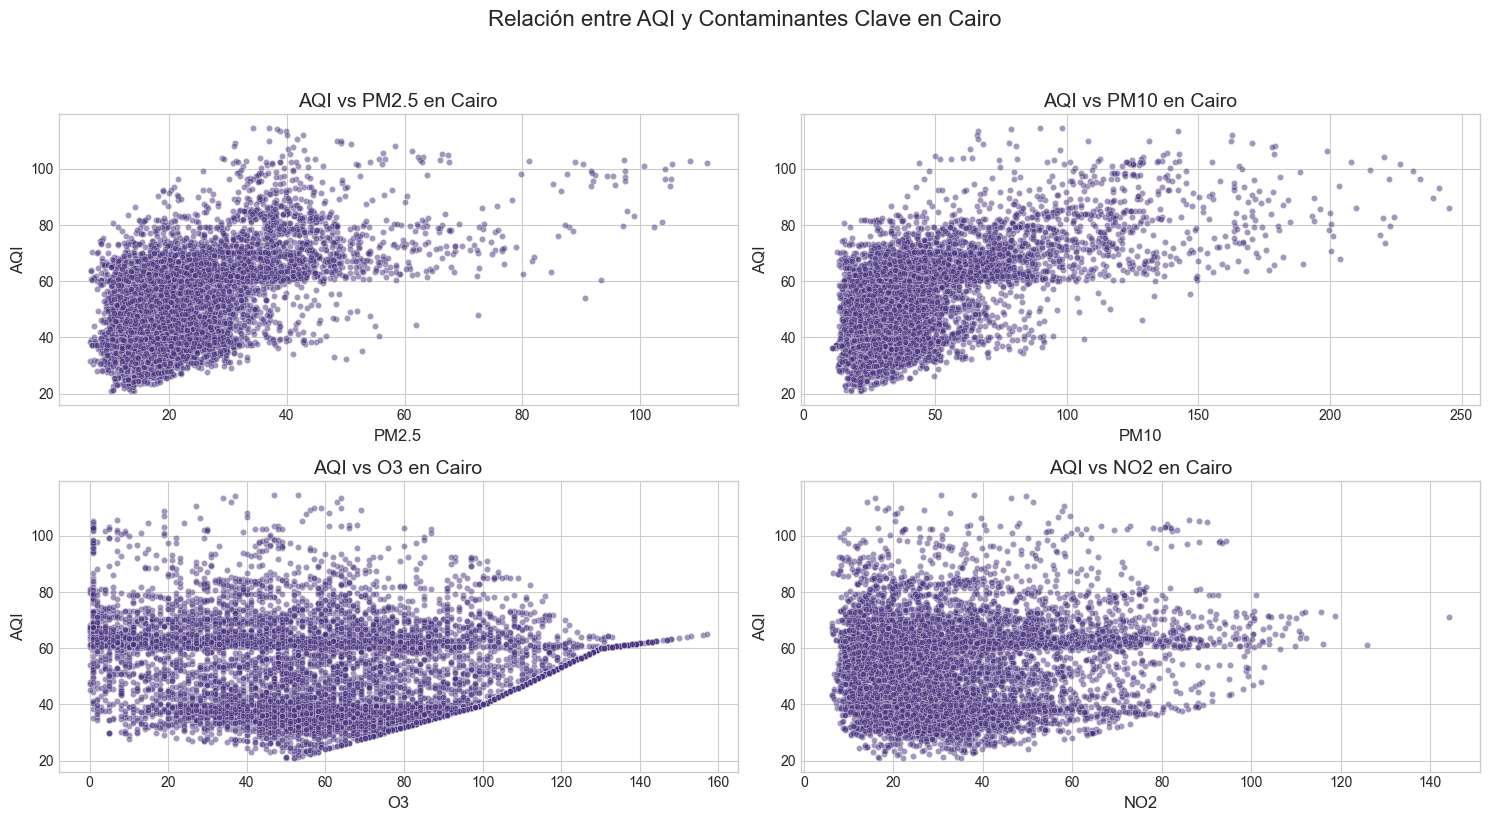

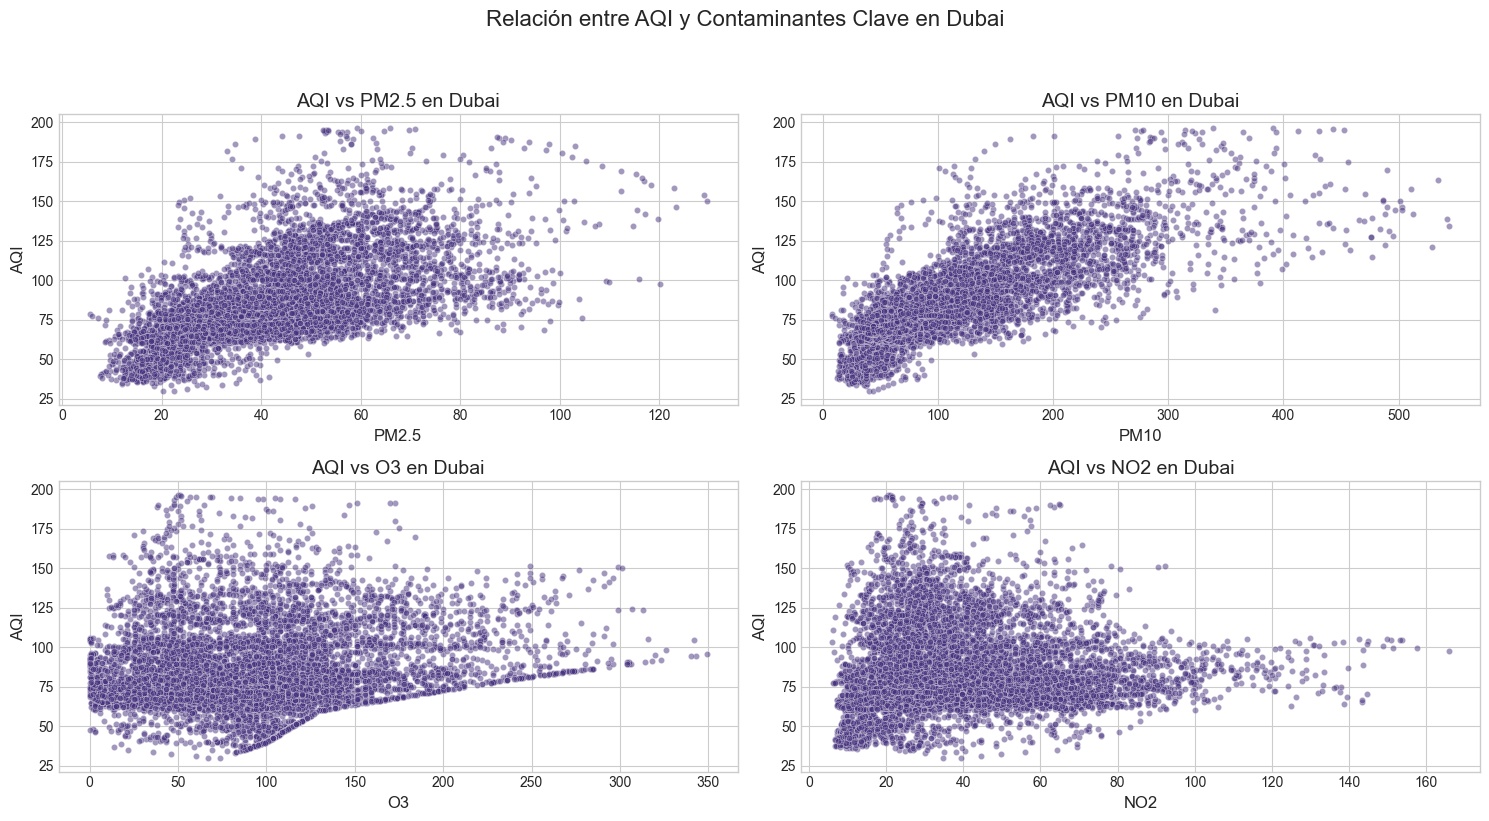

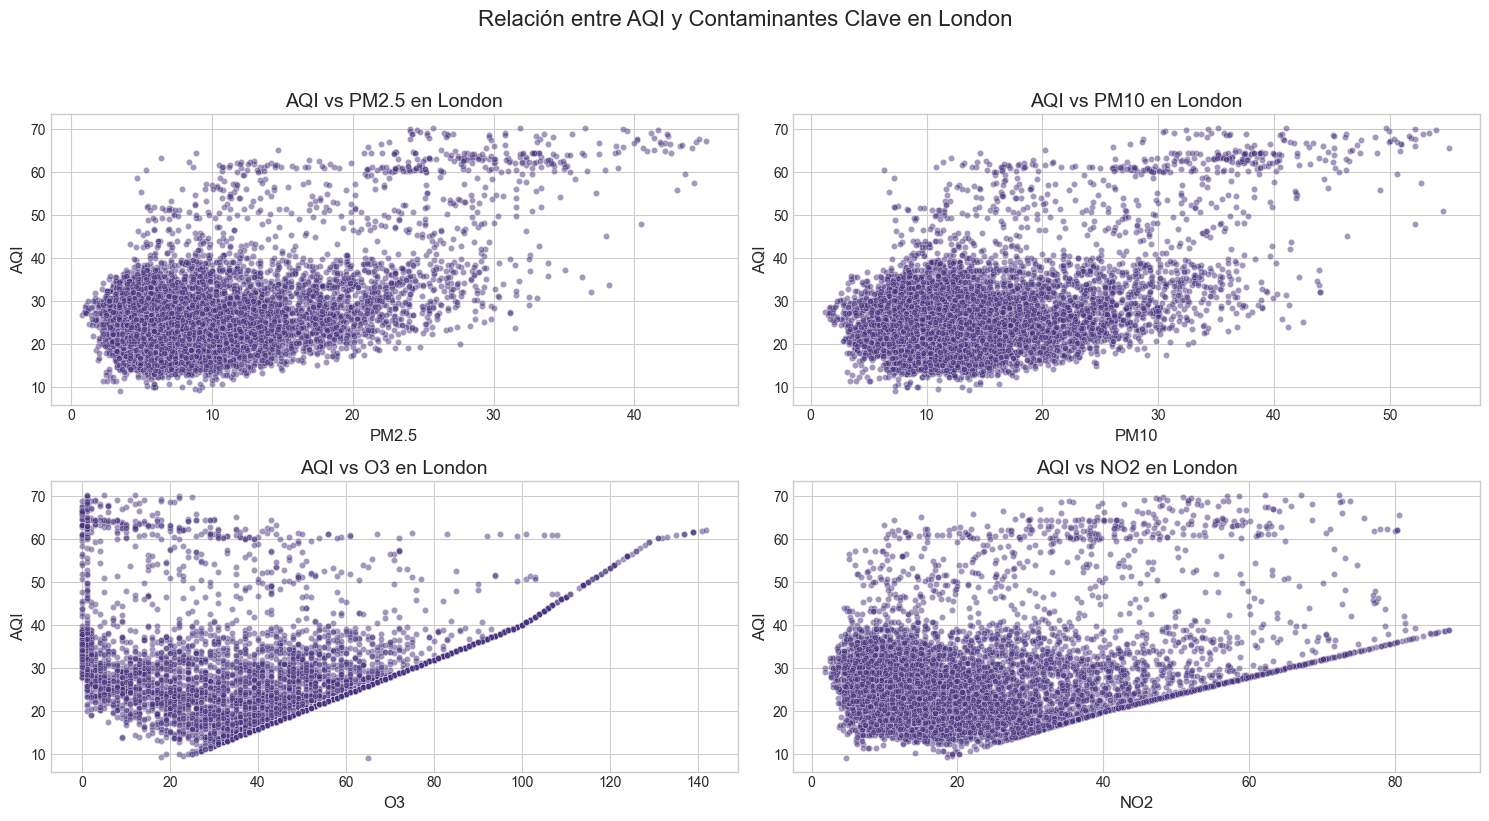

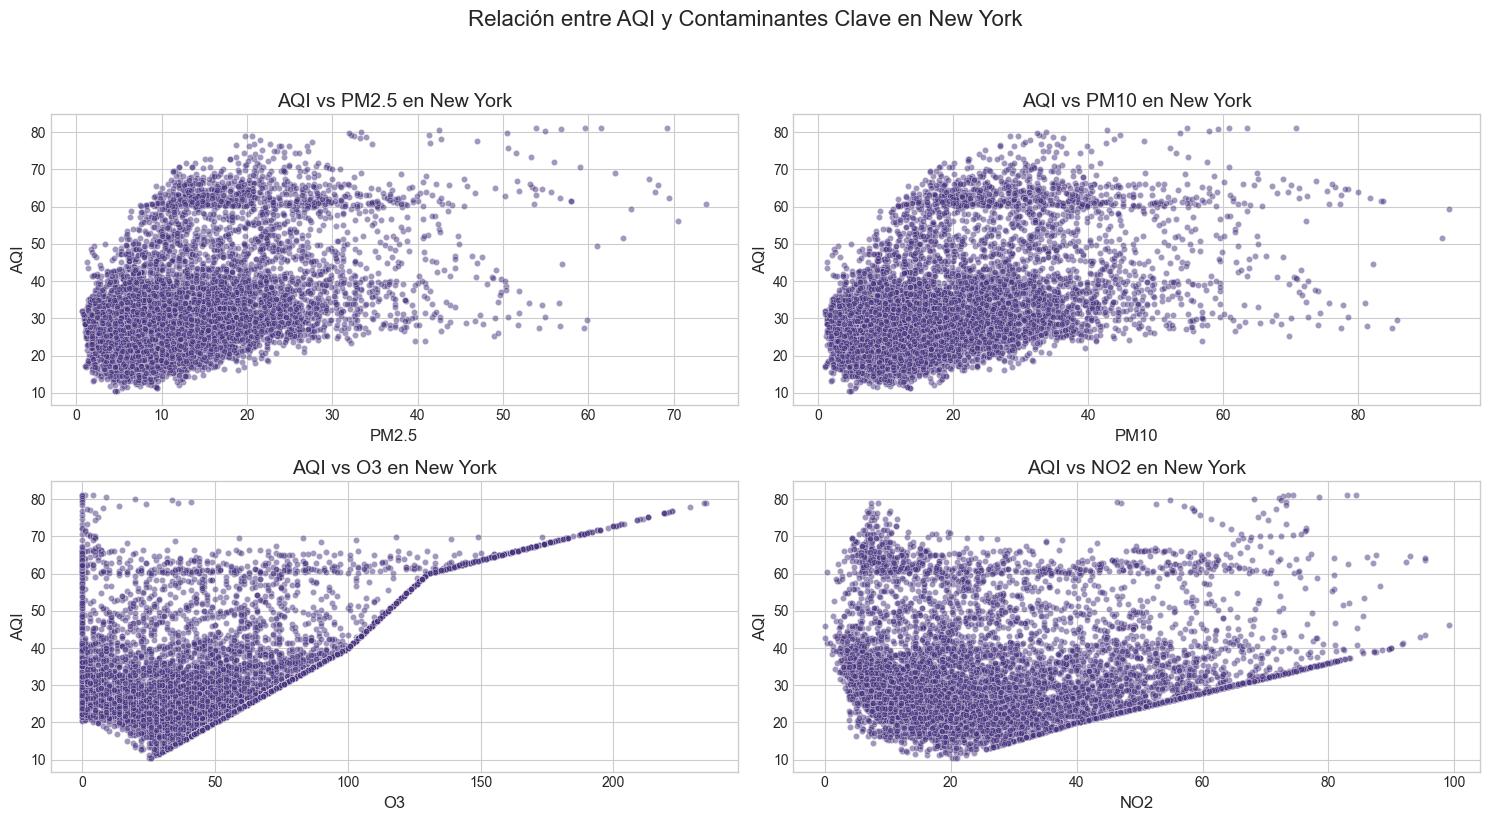

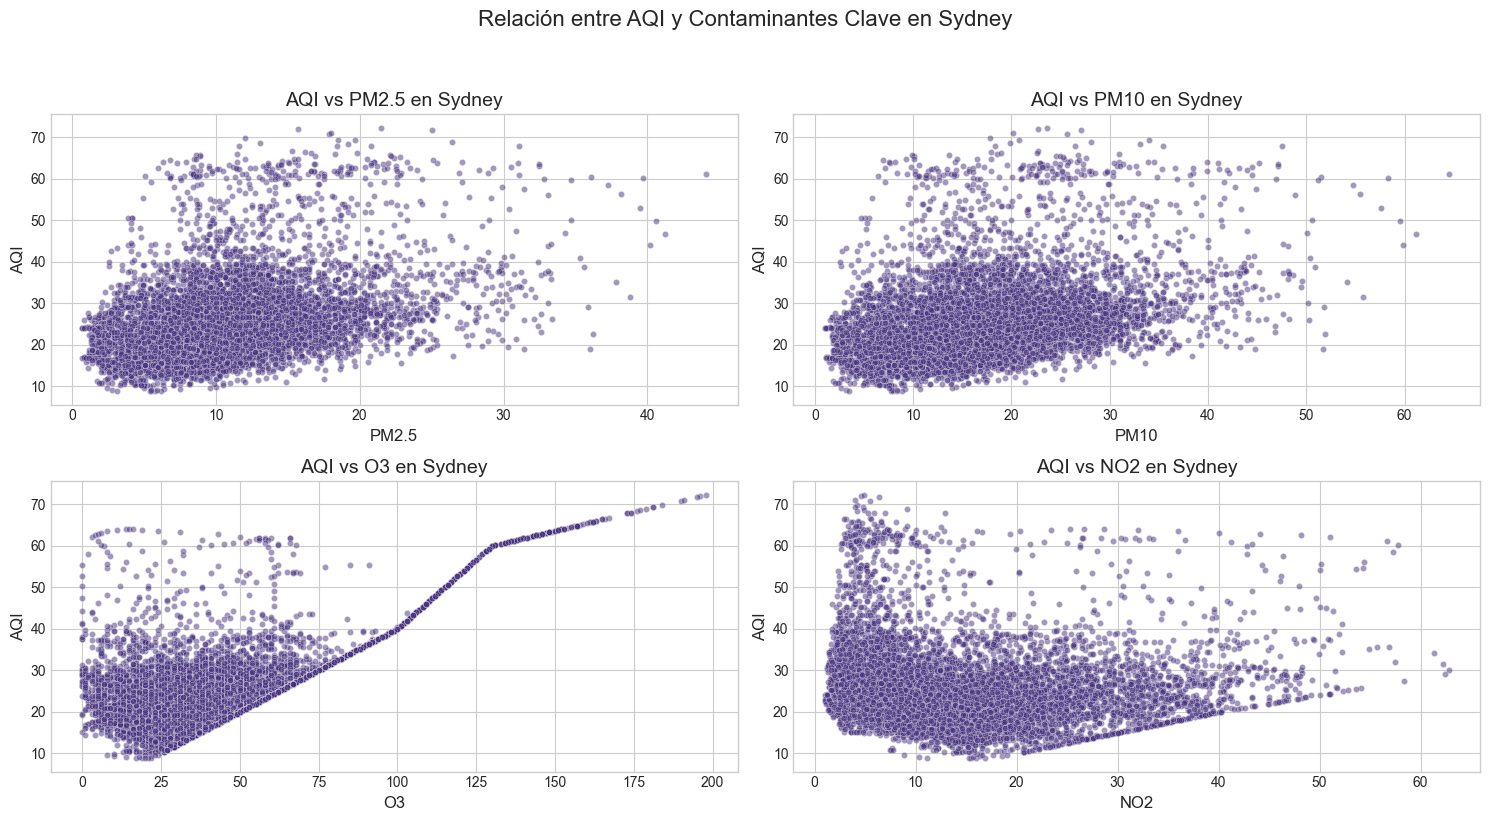

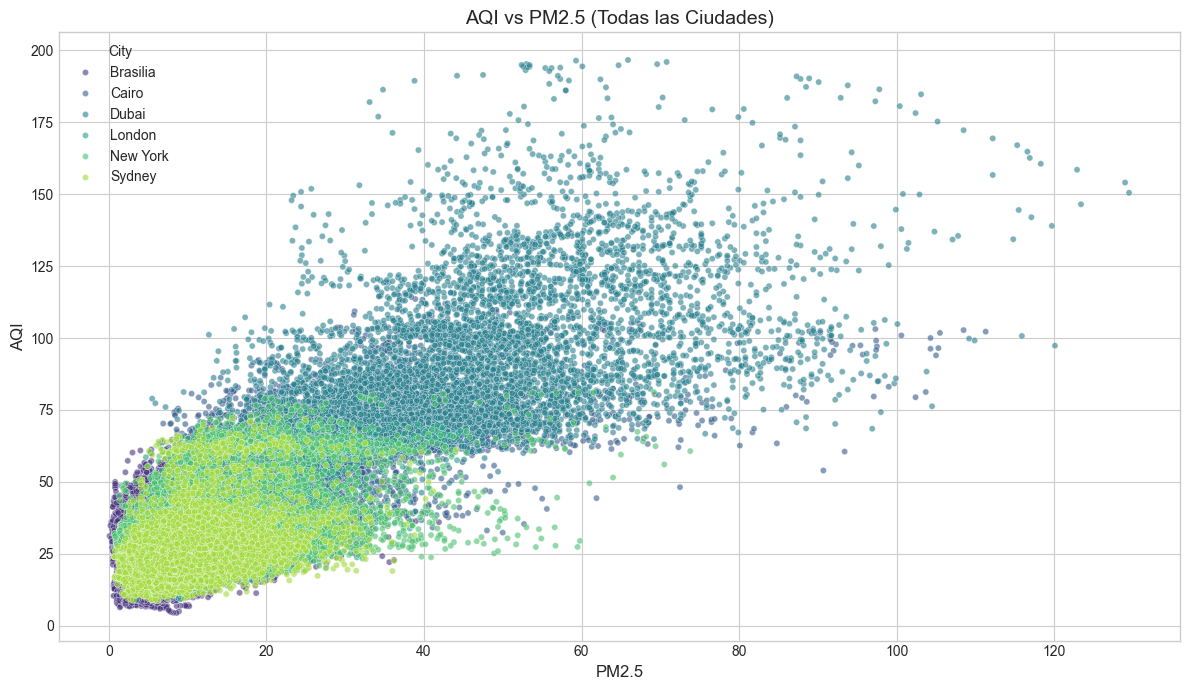


Análisis adicional completado.


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller # Para el test de Dickey-Fuller
import numpy as np # Para np.log si se usa

# --- Configuración Inicial ---
sns.set_style("whitegrid")
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("viridis")

# --- 0. Carga de Datos (Asegúrate de que df esté cargado y 'Date' sea datetime) ---
# ... (tu código de carga aquí, si no está ya cargado en el entorno)
# Ejemplo:
# file_path = os.path.join('CSVs', 'Air_Quality.csv')
# df = pd.read_csv(file_path)
# df['Date'] = pd.to_datetime(df['Date'])

# --- 1. Descartar CO2 y Preparar Datos ---
if 'CO2' in df.columns:
    df = df.drop(columns=['CO2'])
    print("Columna 'CO2' descartada.")

# Crear características temporales
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek  # Lunes=0, Domingo=6
df['Hour'] = df['Date'].dt.hour
df['IsWeekend'] = df['DayOfWeek'].isin([5, 6]) # Sábado y Domingo

# Actualizar lista de columnas numéricas (sin CO2, pero con nuevas features si las consideras numéricas para correlación)
# Por ahora, nos centramos en los contaminantes originales y AQI para la mayoría de análisis
contaminant_cols = ['CO', 'NO2', 'SO2', 'O3', 'PM2.5', 'PM10', 'AQI']

print("\n--- DataFrame con nuevas características temporales (primeras filas) ---")
print(df.head())
print("\n" + "="*50 + "\n")

# --- 2. Análisis de Estacionalidad Semanal y Diferencias Laborable/Fin de Semana ---
print("--- Análisis de Comportamiento Semanal y Laborable/Fin de Semana ---")

for city in df['City'].unique():
    print(f"\n--- Análisis para la Ciudad: {city} ---")
    city_data = df[df['City'] == city].copy() # Usar .copy() para evitar SettingWithCopyWarning

    if city_data.empty:
        print(f"No hay datos para {city}")
        continue

    # Agrupar por día de la semana y calcular la media de AQI y contaminantes
    plt.figure(figsize=(15, 8))
    for i, var in enumerate(contaminant_cols):
        plt.subplot(3, 3, i + 1) # Ajustar layout según el número de contaminantes
        daily_avg = city_data.groupby('DayOfWeek')[var].mean()
        daily_avg.plot(kind='bar', alpha=0.7)
        plt.title(f'Media de {var} por Día de la Semana en {city}')
        plt.xlabel('Día de la Semana (0=Lunes, 6=Domingo)')
        plt.ylabel(f'Media de {var}')
        plt.xticks(rotation=0)
    plt.suptitle(f'Comportamiento Semanal de Contaminantes y AQI en {city}', y=1.03, size=16)
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()

    # Boxplots comparando Laborable vs Fin de Semana para AQI
    plt.figure(figsize=(10, 6))
    sns.boxplot(x='IsWeekend', y='AQI', data=city_data)
    plt.title(f'Distribución del AQI: Laborable vs Fin de Semana en {city}')
    plt.xticks([False, True], ['Día Laborable', 'Fin de Semana'])
    plt.xlabel('')
    plt.ylabel('AQI')
    plt.tight_layout()
    plt.show()

# --- 3. Autocorrelación (ACF y PACF) ---
# Haremos esto para AQI en cada ciudad como ejemplo.
# Podrías hacerlo para otros contaminantes también.
print("\n--- Análisis de Autocorrelación (ACF y PACF) para AQI por Ciudad ---")
lags_to_plot = 72 # Ejemplo: 3 días de lags para datos horarios

for city in df['City'].unique():
    print(f"\n--- ACF/PACF para AQI en: {city} ---")
    city_data_aqi = df[df['City'] == city]['AQI'].dropna() # Asegurarse de no tener NaNs

    if len(city_data_aqi) < lags_to_plot * 2: # Necesitamos suficientes datos
        print(f"No hay suficientes datos en {city} para graficar {lags_to_plot} lags.")
        continue

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    plot_acf(city_data_aqi, lags=lags_to_plot, ax=axes[0], title=f'ACF del AQI en {city}')
    plot_pacf(city_data_aqi, lags=lags_to_plot, ax=axes[1], title=f'PACF del AQI en {city}', method='ywm') # method='ywm' es común
    plt.tight_layout()
    plt.show()

# --- 4. Test de Estacionariedad (Dickey-Fuller Aumentado) ---
# Haremos esto para AQI en cada ciudad como ejemplo.
print("\n--- Test de Estacionariedad (Dickey-Fuller Aumentado) para AQI por Ciudad ---")

def adf_test(timeseries, series_name=""):
    print(f'Resultados del Test de Dickey-Fuller Aumentado para {series_name}:')
    # Asegurarse de que no haya NaNs, ya que adfuller no los maneja
    dftest = adfuller(timeseries.dropna(), autolag='AIC')
    dfoutput = pd.Series(dftest[0:4], index=['Test Statistic', 'p-value', '#Lags Used', 'Number of Observations Used'])
    for key, value in dftest[4].items():
        dfoutput['Critical Value (%s)' % key] = value
    print(dfoutput)
    if dftest[1] <= 0.05:
        print("=> Conclusión: La serie es probablemente estacionaria (se rechaza la hipótesis nula H0)")
    else:
        print("=> Conclusión: La serie es probablemente no estacionaria (no se puede rechazar la hipótesis nula H0)")
    print("-" * 30)

for city in df['City'].unique():
    city_data_aqi = df[df['City'] == city]['AQI']
    if city_data_aqi.isnull().all() or len(city_data_aqi.dropna()) < 20: # Mínimo de datos para el test
        print(f"No hay suficientes datos o todos son NaN para AQI en {city} para el test ADF.")
        continue
    adf_test(city_data_aqi, series_name=f"AQI en {city}")

    # Opcional: si quieres testear otras variables
    # for var in contaminant_cols:
    #     if var == 'AQI': continue # Ya lo hicimos
    #     series_to_test = df[df['City'] == city][var]
    #     if not series_to_test.isnull().all() and len(series_to_test.dropna()) >= 20 :
    #         adf_test(series_to_test, series_name=f"{var} en {city}")

# --- 5. Scatter Plots para ver relaciones ---
# (Ya tenías una matriz de correlación, esto es para visualización directa)
# Haremos un pairplot para ver todas las relaciones entre contaminantes y AQI.
# Esto puede ser intensivo si hay muchos datos. Podemos hacerlo para una ciudad o muestrear.

print("\n--- Generando Scatter Plots (Pairplot) ---")
# Usaremos solo las columnas de contaminantes y AQI
cols_for_pairplot = contaminant_cols

# Opción 1: Pairplot general (puede ser muy denso si hay muchas ciudades y datos)
# print("Generando Pairplot general (puede tardar)...")
# sns.pairplot(df[cols_for_pairplot + ['City']], hue='City', corner=True, plot_kws={'alpha': 0.3, 's': 10}, diag_kind='kde')
# plt.suptitle('Pairplot de Contaminantes y AQI por Ciudad', y=1.02, size=16)
# plt.tight_layout(rect=[0, 0, 1, 0.98])
# plt.show()

# Opción 2: Pairplot por ciudad (más manejable) o un ejemplo de scatter plots específicos
print("Generando Scatter Plots específicos (AQI vs Contaminantes) por ciudad...")
for city in df['City'].unique():
    city_data = df[df['City'] == city]
    if city_data.empty:
        continue

    # Seleccionar solo algunas relaciones clave para no generar demasiados gráficos
    # Por ejemplo, PM2.5, PM10, O3 vs AQI
    key_contaminants_for_scatter = ['PM2.5', 'PM10', 'O3', 'NO2']
    num_scatters = len(key_contaminants_for_scatter)

    if num_scatters == 0: continue

    plt.figure(figsize=(15, (num_scatters // 2 + num_scatters % 2) * 4 )) # Ajustar tamaño
    for i, contam in enumerate(key_contaminants_for_scatter):
        if contam not in city_data.columns: continue
        plt.subplot((num_scatters // 2 + num_scatters % 2), 2, i + 1)
        sns.scatterplot(x=contam, y='AQI', data=city_data, alpha=0.5, s=20)
        plt.title(f'AQI vs {contam} en {city}')
    plt.suptitle(f'Relación entre AQI y Contaminantes Clave en {city}', y=1.02, size=16)
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()

# Otra opción: Scatter plot de AQI vs PM2.5 coloreado por ciudad
plt.figure(figsize=(12, 7))
sns.scatterplot(x='PM2.5', y='AQI', hue='City', data=df, alpha=0.6, s=20)
plt.title('AQI vs PM2.5 (Todas las Ciudades)')
plt.tight_layout()
plt.show()


# --- Consideraciones Adicionales (No implementado directamente aquí pero para pensar) ---
# - Transformaciones Logarítmicas: Si la asimetría es muy fuerte, podrías probar np.log1p(df[col])
#   y rehacer algunos análisis para ver si las relaciones se vuelven más lineales o las distribuciones más normales.
# - Descomposición Estacional más Detallada: `seasonal_decompose` puede usarse con diferentes periodos
#   (ej. 24 para estacionalidad diaria si tus datos son horarios, 24*7 para semanal).

print("\nAnálisis adicional completado.")


--- Análisis de Patrones Horarios de Contaminantes y AQI por Ciudad ---

--- Patrones Horarios para la Ciudad: Brasilia ---


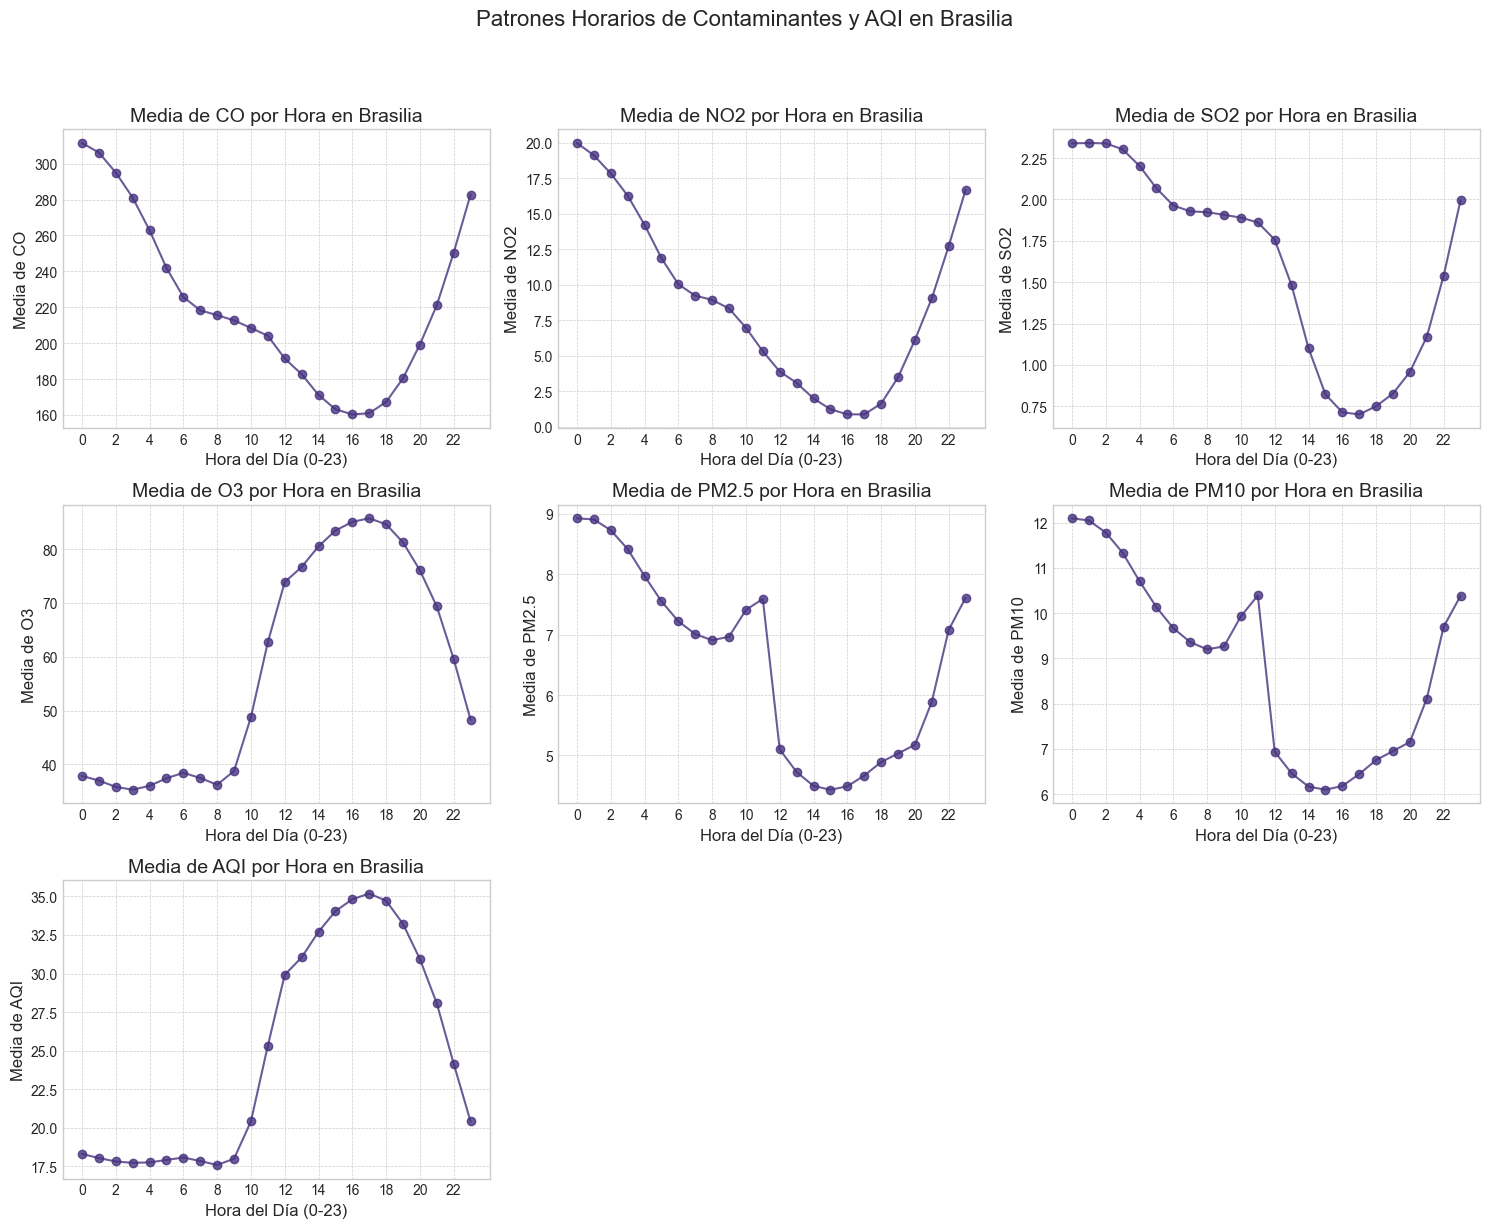


--- Patrones Horarios para la Ciudad: Cairo ---


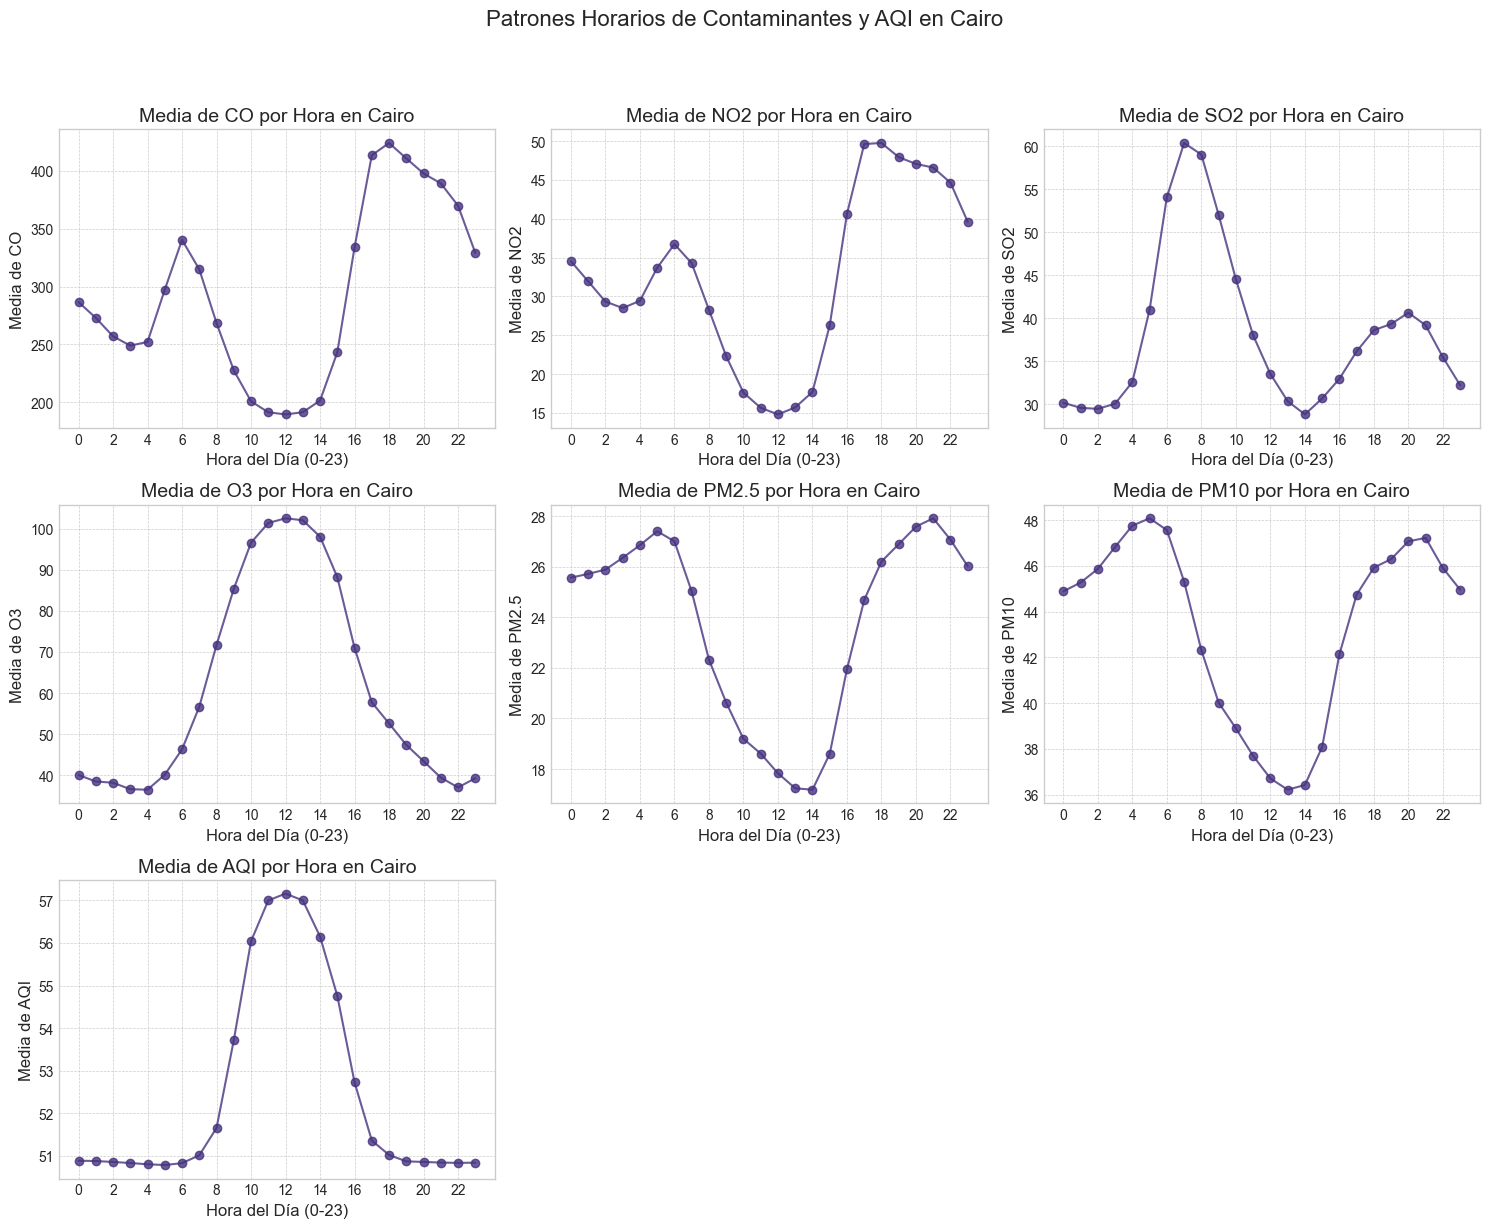


--- Patrones Horarios para la Ciudad: Dubai ---


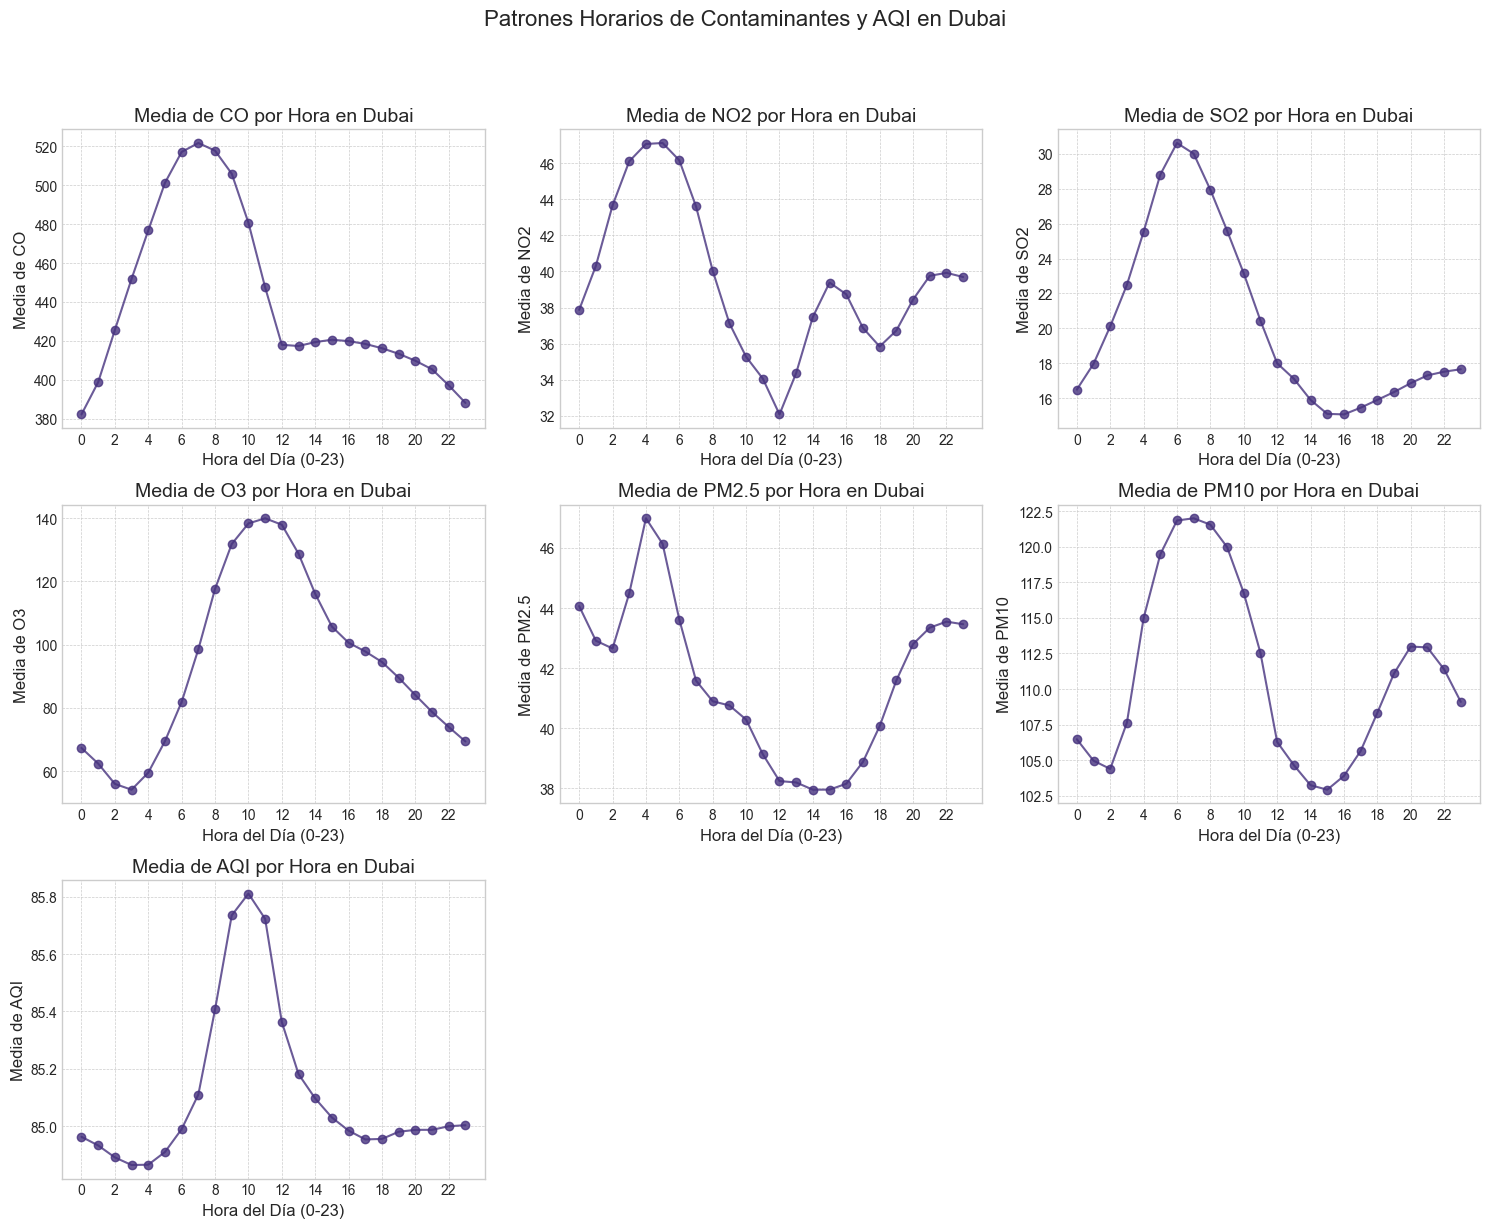


--- Patrones Horarios para la Ciudad: London ---


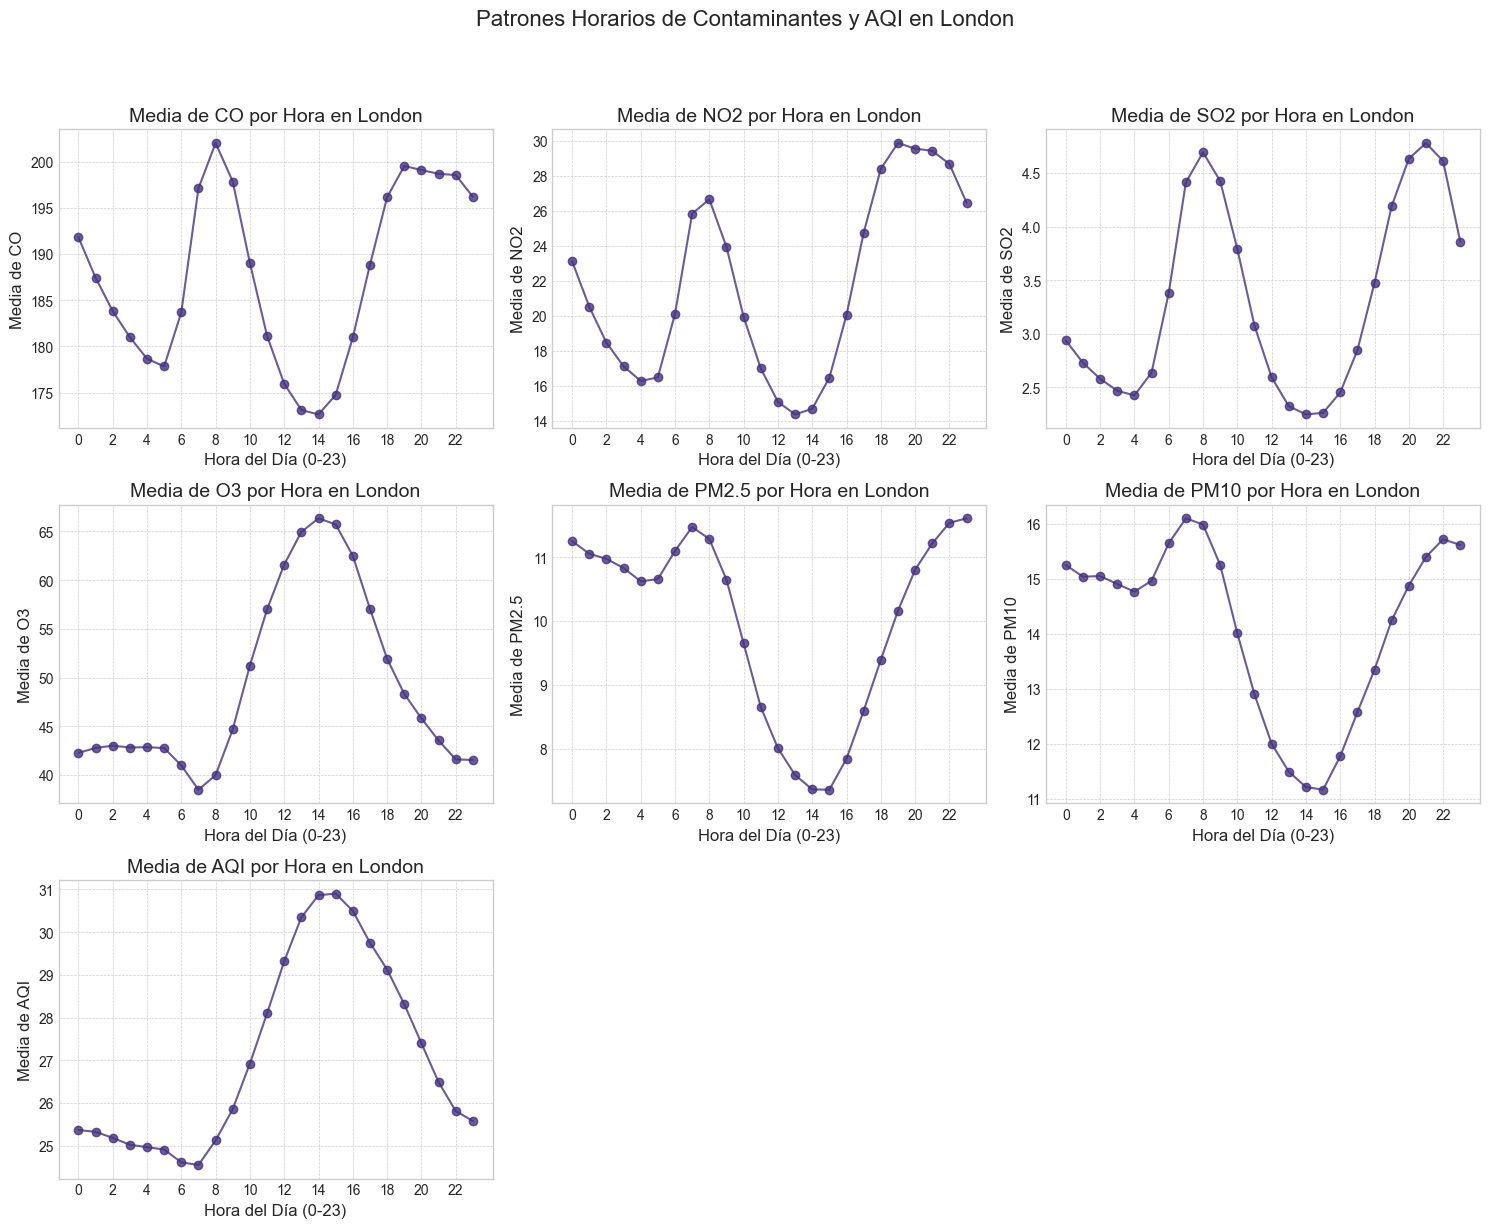


--- Patrones Horarios para la Ciudad: New York ---


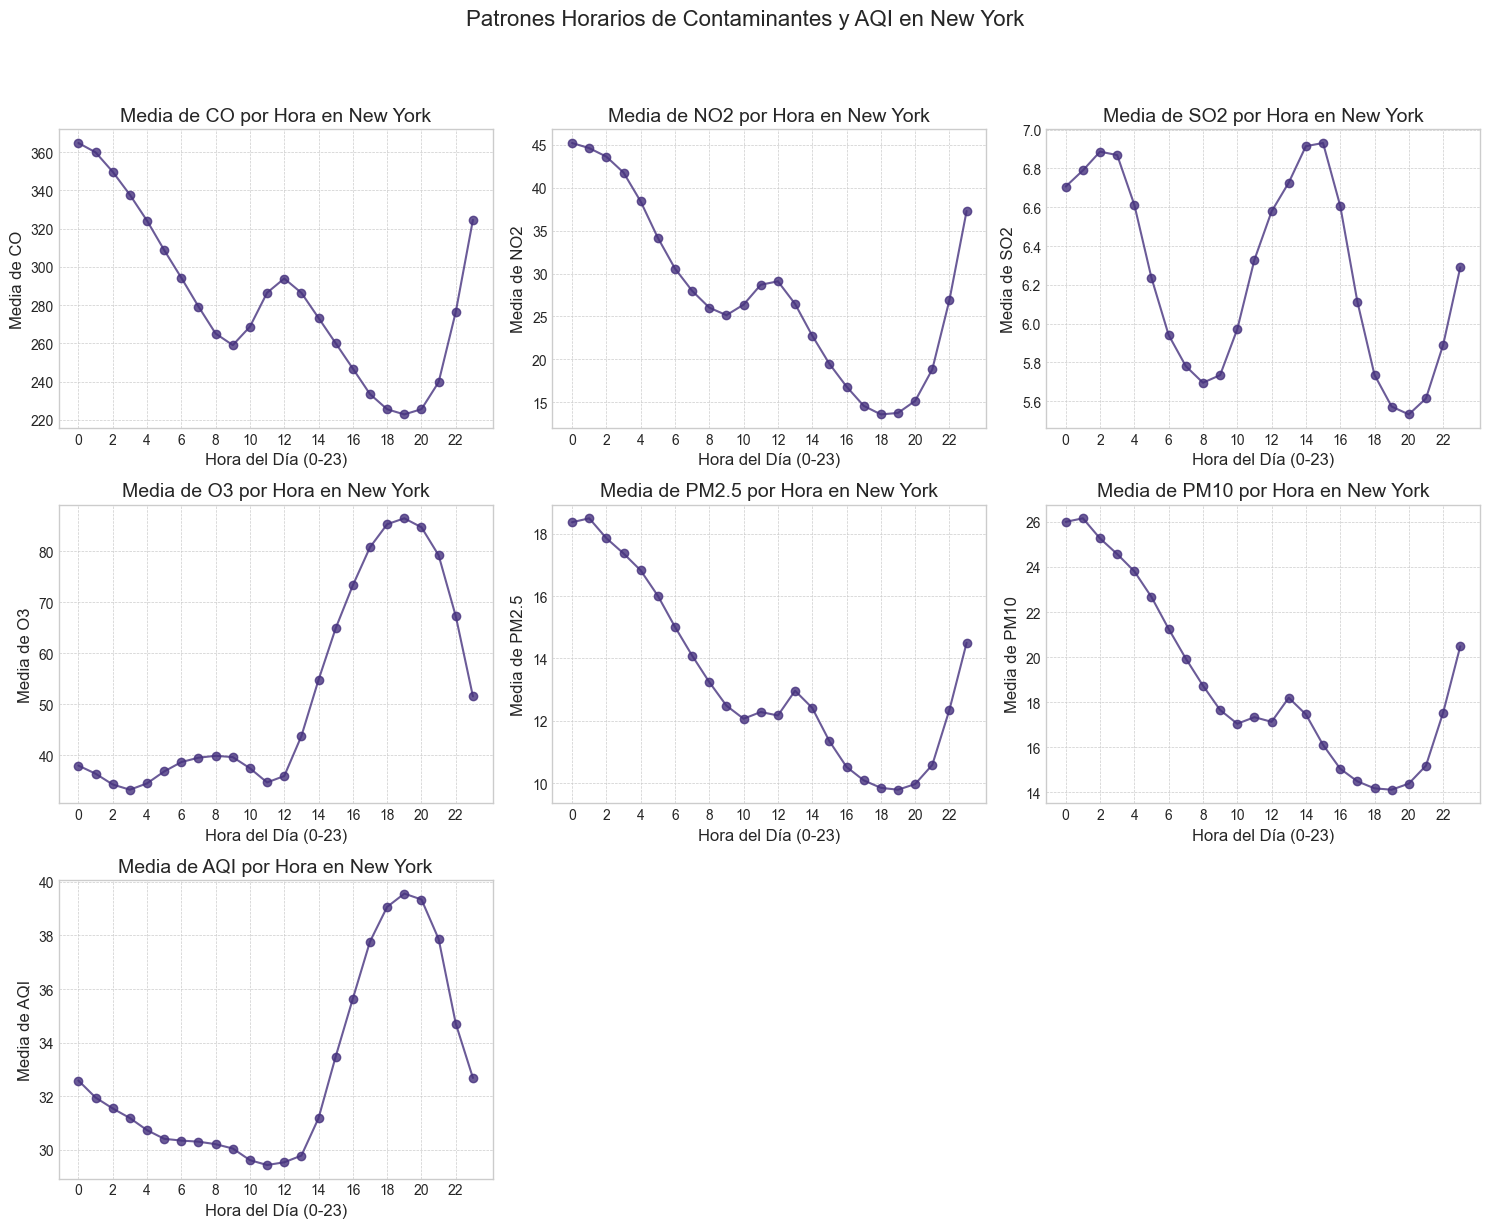


--- Patrones Horarios para la Ciudad: Sydney ---


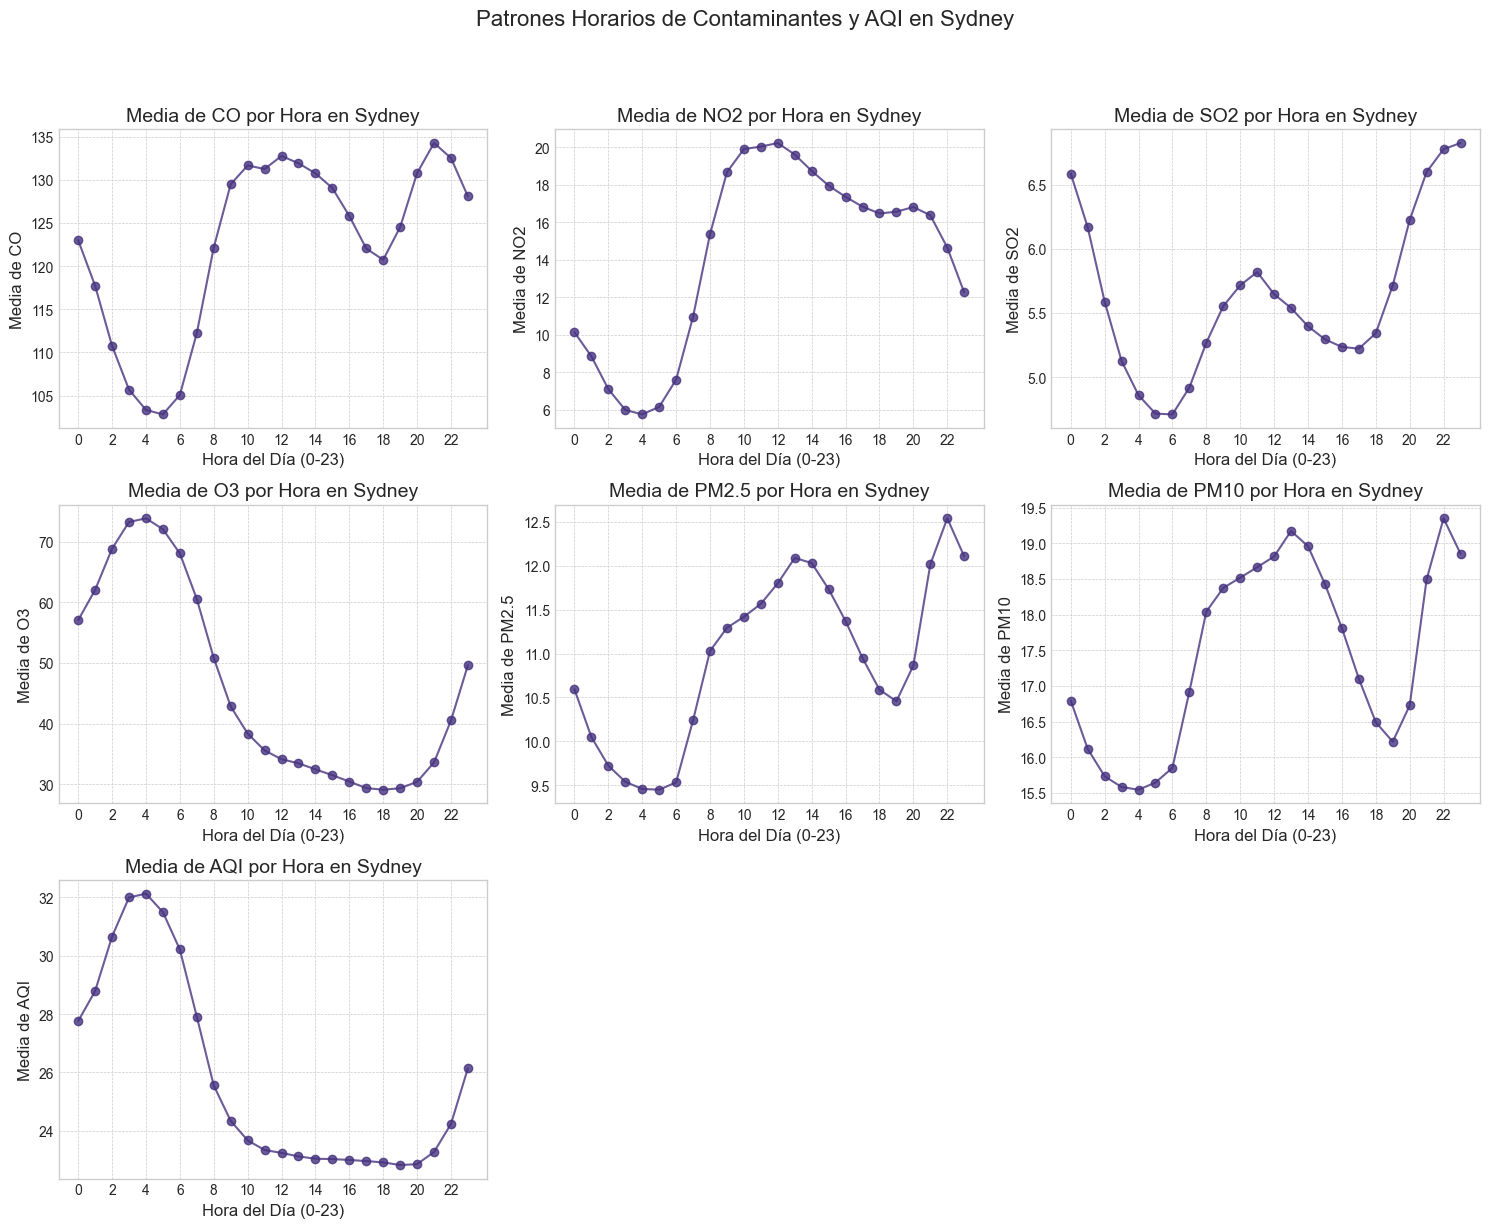


--- Comparación de Patrones Horarios del AQI entre Ciudades ---


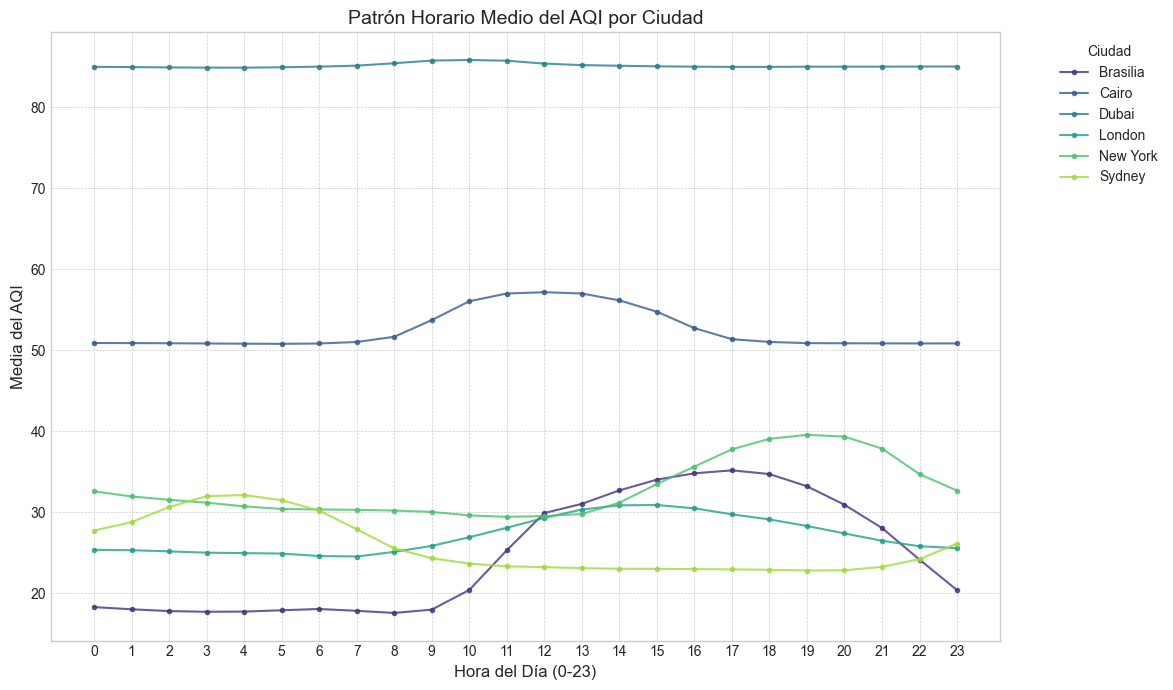


Análisis de patrones horarios completado.


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# --- Configuración Inicial ---
sns.set_style("whitegrid")
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("viridis") # O cualquier otra paleta que te guste, "tab10" también es buena para distinguir.

# --- 0. Carga de Datos y Preparación (Asegúrate de que df esté cargado y 'Date' sea datetime) ---
# ... (tu código de carga aquí, si no está ya cargado en el entorno)
# Asumimos que 'Hour' ya fue creada como: df['Hour'] = df['Date'].dt.hour
# Asumimos que 'contaminant_cols' está definida:
# contaminant_cols = ['CO', 'NO2', 'SO2', 'O3', 'PM2.5', 'PM10', 'AQI']

# Verificar si la columna 'Hour' existe, si no, crearla
if 'Hour' not in df.columns:
    if 'Date' in df.columns and pd.api.types.is_datetime64_any_dtype(df['Date']):
        df['Hour'] = df['Date'].dt.hour
        print("Columna 'Hour' creada.")
    else:
        print("Error: La columna 'Date' no existe o no es de tipo datetime. No se puede crear 'Hour'.")
        # Aquí podrías detener la ejecución o manejar el error como prefieras
        exit()


# --- 6. Análisis de Patrones Horarios ---
print("\n--- Análisis de Patrones Horarios de Contaminantes y AQI por Ciudad ---")

for city in df['City'].unique():
    print(f"\n--- Patrones Horarios para la Ciudad: {city} ---")
    city_data = df[df['City'] == city].copy()

    if city_data.empty:
        print(f"No hay datos para {city}")
        continue

    # Agrupar por hora y calcular la media de AQI y contaminantes
    # El layout se ajustará al número de variables en contaminant_cols
    num_vars = len(contaminant_cols)
    n_cols_plot = 3  # Puedes ajustar el número de columnas
    n_rows_plot = (num_vars + n_cols_plot - 1) // n_cols_plot

    plt.figure(figsize=(n_cols_plot * 5, n_rows_plot * 4)) # Ajustar tamaño dinámicamente
    for i, var in enumerate(contaminant_cols):
        plt.subplot(n_rows_plot, n_cols_plot, i + 1)
        hourly_avg = city_data.groupby('Hour')[var].mean()
        hourly_avg.plot(kind='line', marker='o', linestyle='-', alpha=0.8, legend=False) # Cambiado a line plot
        plt.title(f'Media de {var} por Hora en {city}')
        plt.xlabel('Hora del Día (0-23)')
        plt.ylabel(f'Media de {var}')
        plt.xticks(range(0, 24, 2)) # Marcas cada 2 horas
        plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.suptitle(f'Patrones Horarios de Contaminantes y AQI en {city}', y=1.02, size=16) # Ajustar y
    plt.tight_layout(rect=[0, 0, 1, 0.98]) # Ajustar rect
    plt.show()

# --- Opcional: Comparar el patrón horario del AQI entre todas las ciudades en un solo gráfico ---
print("\n--- Comparación de Patrones Horarios del AQI entre Ciudades ---")
plt.figure(figsize=(14, 7))
for city in df['City'].unique():
    city_data = df[df['City'] == city]
    if not city_data.empty:
        hourly_aqi_avg = city_data.groupby('Hour')['AQI'].mean()
        hourly_aqi_avg.plot(kind='line', marker='.', linestyle='-', label=city, alpha=0.8)

plt.title('Patrón Horario Medio del AQI por Ciudad')
plt.xlabel('Hora del Día (0-23)')
plt.ylabel('Media del AQI')
plt.xticks(range(0, 24, 1))
plt.legend(title='Ciudad', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.tight_layout(rect=[0, 0, 0.85, 1]) # Ajustar para la leyenda
plt.show()

print("\nAnálisis de patrones horarios completado.")

ACF PACF para paper

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import seaborn as sns
import os

# --- Style and Data Loading Configuration ---
sns.set_style("whitegrid")
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 10) # Adjusted for vertical layout
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

# --- Load Data ---
# Ensure this path is correct relative to where you run the script.
try:
    file_path =  os.path.join('CSVs', 'Air_Quality.csv')
    if not os.path.exists(file_path):
        # Fallback for different directory structures
        file_path = os.path.join('..', 'CSVs', 'Air_Quality.csv') 
    df = pd.read_csv(file_path)
    df['Date'] = pd.to_datetime(df['Date'])
except FileNotFoundError:
    print(f"Error: Could not find the data file. Please check the path.")
    # Create a dummy dataframe to avoid crashing if file is not found
    df = pd.DataFrame()

# --- Plotting ACF and PACF for AQI in Brasilia ---
if not df.empty:
    city_to_plot = 'Brasilia'
    lags_to_plot = 72  # 3 days of hourly lags

    # Filter data for the specific city and drop any missing values in the target column
    city_data_aqi = df[df['City'] == city_to_plot]['AQI'].dropna()

    if len(city_data_aqi) > lags_to_plot * 2:
        # Create a figure with 2 subplots arranged vertically (2 rows, 1 column)
        fig, axes = plt.subplots(2, 1, figsize=(10, 10)) # Adjusted figsize for vertical aspect
        
        # Plot ACF on the top subplot
        plot_acf(city_data_aqi, lags=lags_to_plot, ax=axes[0])
        axes[0].set_title(f'Autocorrelation Function (ACF) of AQI in {city_to_plot}')
        axes[0].set_xlabel('Lag (Hours)')
        axes[0].set_ylabel('ACF')

        # Plot PACF on the bottom subplot
        plot_pacf(city_data_aqi, lags=lags_to_plot, ax=axes[1], method='ywm')
        axes[1].set_title(f'Partial Autocorrelation Function (PACF) of AQI in {city_to_plot}')
        axes[1].set_xlabel('Lag (Hours)')
        axes[1].set_ylabel('PACF')

        # Improve layout and save the figure
        plt.tight_layout(pad=2.0)
        output_filename = 'acf_pacf_vertical_brasilia.png'
        plt.savefig(output_filename, dpi=300)
        plt.show()
        
        print(f"Figure saved as '{output_filename}'")
    else:
        print(f"Not enough data for {city_to_plot} to generate plots with {lags_to_plot} lags.")
else:
    print("DataFrame is empty. Cannot generate plots.")

Error: Could not find the data file. Please check the path.
DataFrame is empty. Cannot generate plots.
